In [1]:
%load_ext autoreload
%autoreload 2

import torch
from torch import nn
from torch.nn import functional as F

import matplotlib.pyplot as plt
import numpy as np

from src.utils import DEVICE, CKPT_DIR, FIG_DIR, set_seed, save_history, load_history, show_grid
from src.data import get_dataloaders, CLASSES
from src.metrics import recon_metrics, latency_ms
from src.train import train_classifier, evaluate_classifier, extract_latents, fit

 ### Dataset Preparation

In [2]:
set_seed(42) # random, numpy, torch

BATCH_SIZE = 256
EPOCHS = 20

# 70k samples (train 60k + test 10k), stratified split 80:10:10
# batch 256, shuffle=True for train and shuffle=False for validation/test
train_dl, val_dl, test_dl = get_dataloaders(batch_size=BATCH_SIZE)

print(len(train_dl.dataset), len(val_dl.dataset), len(test_dl.dataset))
print(DEVICE)

56000 7000 7000
cuda


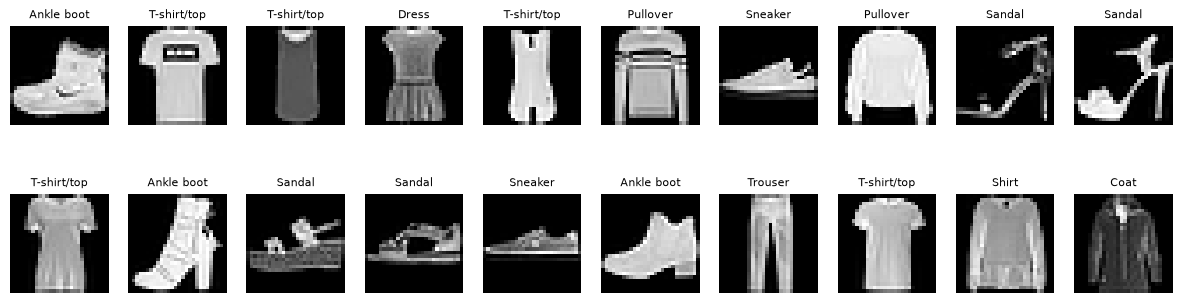

In [3]:
# test show image
x = train_dl.dataset.dataset.datasets[0].data
classes = train_dl.dataset.dataset.datasets[0].classes
y_idx = train_dl.dataset.dataset.datasets[0].targets
y = [classes[i] for i in y_idx]

sample_x, sample_y = x[:20], y[:20]

fig, axes = plt.subplots(2, 10, figsize=(15, 4))
for c, ax in enumerate(axes.flat):
    ax.imshow(sample_x[c].numpy(), cmap="gray")
    ax.set_title(sample_y[c], fontsize=8)
    ax.axis("off")
plt.show()

MLP: step 1 (train classifier)

In [4]:
# base MLP model to recreate encoder architecture: 784 -> 256 -> 64 -> 10
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, 64)
        self.fc3 = nn.Linear(64, 10)

    def forward(self, x):
        x = x.view(x.size(0), -1)  # (B,1,28,28) -> (B,784) flatten
        h = F.relu(self.fc1(x))
        z = F.relu(self.fc2(h))    # latent
        return self.fc3(z), z      # logits, z

In [5]:
# Train, Validate, Test
set_seed(42)
model = MLP().to(DEVICE)
opt = torch.optim.Adam(model.parameters(), lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0)

history = train_classifier("mlp", model, opt, train_dl, val_dl, epochs=EPOCHS)

test_loss, test_acc = evaluate_classifier(model, test_dl)
print("Test Loss    :", test_loss)
print("Test Accuracy:", test_acc)

Epoch   1: train_loss=0.6765 | train_acc=0.7708 | val_loss=0.4835 | val_acc=0.8289 | 3.7s
Epoch   2: train_loss=0.4343 | train_acc=0.8473 | val_loss=0.4201 | val_acc=0.8491 | 3.3s
Epoch   3: train_loss=0.3922 | train_acc=0.8613 | val_loss=0.3978 | val_acc=0.8551 | 4.5s
Epoch   4: train_loss=0.3600 | train_acc=0.8701 | val_loss=0.3765 | val_acc=0.8626 | 4.5s
Epoch   5: train_loss=0.3410 | train_acc=0.8769 | val_loss=0.3595 | val_acc=0.8693 | 4.5s
Epoch   6: train_loss=0.3255 | train_acc=0.8824 | val_loss=0.3527 | val_acc=0.8733 | 4.5s
Epoch   7: train_loss=0.3107 | train_acc=0.8869 | val_loss=0.3401 | val_acc=0.8771 | 4.5s
Epoch   8: train_loss=0.2954 | train_acc=0.8908 | val_loss=0.3525 | val_acc=0.8706 | 4.5s
Epoch   9: train_loss=0.2922 | train_acc=0.8930 | val_loss=0.3340 | val_acc=0.8789 | 4.5s
Epoch  10: train_loss=0.2776 | train_acc=0.8987 | val_loss=0.3343 | val_acc=0.8810 | 4.5s
Epoch  11: train_loss=0.2692 | train_acc=0.9015 | val_loss=0.3288 | val_acc=0.8777 | 4.6s
Epoch  12:

In [6]:
# save weights (for Step 2-3)
W1 = model.fc1.weight.detach()   # (256, 784)
W2 = model.fc2.weight.detach()   # (64, 256)
W3 = model.fc3.weight.detach()   # (10, 64)
torch.save({"W1": W1.cpu(), "W2": W2.cpu(), "W3": W3.cpu()}, CKPT_DIR / "mlp_weights.pt")

# save z_mlp of the test set (for Step 3-5)
z_mlp, y_test = extract_latents(model, test_dl)   # (7000, 64), (7000,)
torch.save({"z": z_mlp, "y": y_test}, CKPT_DIR / "z_mlp.pt")
print(W1.shape, W2.shape, W3.shape, z_mlp.shape)

torch.Size([256, 784]) torch.Size([64, 256]) torch.Size([10, 64]) torch.Size([7000, 64])


MLP: Step 2 (Top-Down Weight Transportation -> reverse from one hot to pixels)

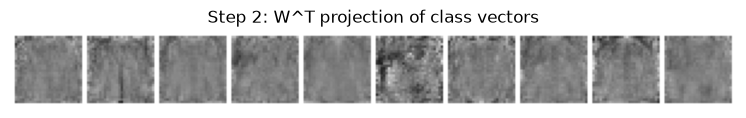

In [7]:
Y = torch.eye(10, device=W3.device) # 10 sample one hot 1 per class

z_hat  = F.relu(Y @ W3)             # (10,10) @ (10,64)   -> (10,64)  
h1_hat = F.relu(z_hat @ W2)         # (10,64) @ (64,256)  -> (10,256) 
x_hat  = torch.sigmoid(h1_hat @ W1) # (10,256) @ (256,784)-> (10,784) 

show_grid(x_hat.view(10, 1, 28, 28), nrow=10, title="Step 2: W^T projection of class vectors")

MLP: Step 3 (reverse latent to pixels)

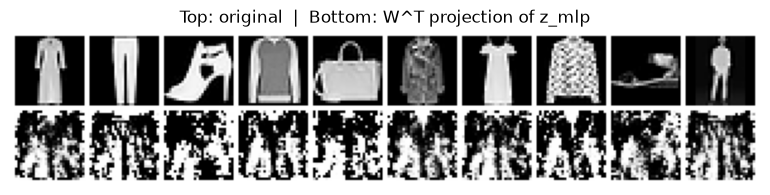

In [8]:
x_test, y_lbl = next(iter(test_dl)) # first test batch, same order as z_mlp
x_orig = x_test[:10].to(W2.device)  # (10,1,28,28)
z = z_mlp[:10].to(W2.device)        # (10,64), z of exactly those 10 images

h1_back = F.relu(z @ W2)            # (10,64) @ (64,256)  -> (10,256)
x_back = torch.sigmoid(h1_back @ W1)# (10,256) @ (256,784) -> (10,784)

show_grid(torch.cat([x_orig, x_back.view(10, 1, 28, 28)]), nrow=10,
          title="Top: original  |  Bottom: W^T projection of z_mlp")

MLP: Step 4 part 1 (frozen mlp classifier + decoder)

In [9]:
# 64 -> 256 -> 784
class Decoder(nn.Module):
    def __init__(self, z_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim, 256), nn.ReLU(),
            nn.Linear(256, 784), nn.Sigmoid())
    def forward(self, z):
        return self.net(z)

In [10]:
def frozen_dec_loss(decoder, x, y):
    with torch.no_grad():
        _, z = model(x) # get latent space from encoder
    x_hat = decoder(z)  # get reconstructed pixels
    return F.mse_loss(x_hat, x.view(x.size(0), -1))

# freeze encoder weights
for p in model.parameters():
    p.requires_grad = False
model.eval()

set_seed(42)
decoder = Decoder().to(DEVICE)
opt_dec = torch.optim.Adam(decoder.parameters(), lr=1e-3)

# train, validate, and eval
hist_dec = fit("mlp_frozen_decoder", decoder, frozen_dec_loss, opt_dec, train_dl, val_dl, epochs=EPOCHS)
res_mlp_dec = recon_metrics(lambda x: decoder(model(x)[1]))

mlp_frozen_decoder ep   1 | train 0.04146 | val 0.02791 | 5.2s
mlp_frozen_decoder ep   2 | train 0.02558 | val 0.02370 | 5.2s
mlp_frozen_decoder ep   3 | train 0.02260 | val 0.02216 | 4.7s
mlp_frozen_decoder ep   4 | train 0.02112 | val 0.02061 | 4.9s
mlp_frozen_decoder ep   5 | train 0.02024 | val 0.01999 | 4.7s
mlp_frozen_decoder ep   6 | train 0.01961 | val 0.01943 | 5.3s
mlp_frozen_decoder ep   7 | train 0.01914 | val 0.01910 | 4.7s
mlp_frozen_decoder ep   8 | train 0.01876 | val 0.01864 | 4.8s
mlp_frozen_decoder ep   9 | train 0.01845 | val 0.01836 | 5.3s
mlp_frozen_decoder ep  10 | train 0.01814 | val 0.01828 | 5.1s
mlp_frozen_decoder ep  11 | train 0.01789 | val 0.01796 | 5.2s
mlp_frozen_decoder ep  12 | train 0.01772 | val 0.01770 | 5.3s
mlp_frozen_decoder ep  13 | train 0.01749 | val 0.01758 | 4.7s
mlp_frozen_decoder ep  14 | train 0.01731 | val 0.01739 | 5.3s
mlp_frozen_decoder ep  15 | train 0.01717 | val 0.01724 | 4.9s
mlp_frozen_decoder ep  16 | train 0.01704 | val 0.01726

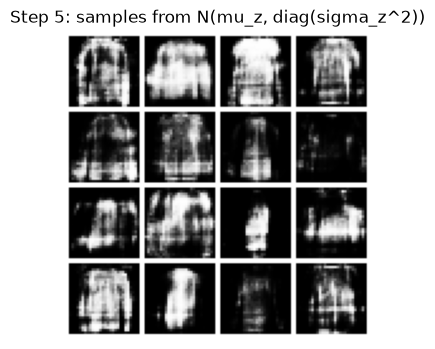

In [11]:
mu, sigma = z_mlp.mean(0), z_mlp.std(0) # per-dimension, shape (64,)
set_seed(42)
z_rand = (mu + sigma * torch.randn(16, 64)).to(DEVICE)
imgs = decoder(z_rand).view(16, 1, 28, 28)
show_grid(imgs, nrow=4, title="Step 5: samples from N(mu_z, diag(sigma_z^2))")

Vanilla Autoencoder 

In [12]:
# 784 -> 256 -> 64 -> 256 -> 784
class AE(nn.Module):
    def __init__(self, z_dim=64):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Flatten(),                         # (B,1,28,28) -> (B,784)
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, z_dim), nn.ReLU())     # latent h, (B,64)
        self.dec = nn.Sequential(
            nn.Linear(z_dim, 256), nn.ReLU(),
            nn.Linear(256, 784), nn.Sigmoid())    # pixels in [0,1], (B,784)

    def forward(self, x):
        h = self.enc(x)
        return self.dec(h), h # x_hat, latent

def ae_loss(model, x, y):
    x_hat, _ = model(x)
    return F.mse_loss(x_hat, x.flatten(1))

In [13]:
set_seed(42)
ae = AE().to(DEVICE)
opt_ae = torch.optim.Adam(ae.parameters(), lr=1e-3)
print("parameters:", sum(p.numel() for p in ae.parameters()))

# train and validate
hist_ae = fit("ae", ae, ae_loss, opt_ae, train_dl, val_dl, epochs=EPOCHS)

parameters: 435536
ae ep   1 | train 0.04663 | val 0.02386 | 3.9s
ae ep   2 | train 0.02125 | val 0.01926 | 5.1s
ae ep   3 | train 0.01810 | val 0.01725 | 4.8s
ae ep   4 | train 0.01633 | val 0.01565 | 4.6s
ae ep   5 | train 0.01502 | val 0.01453 | 4.8s
ae ep   6 | train 0.01406 | val 0.01383 | 4.7s
ae ep   7 | train 0.01334 | val 0.01309 | 4.7s
ae ep   8 | train 0.01278 | val 0.01256 | 4.6s
ae ep   9 | train 0.01233 | val 0.01231 | 4.8s
ae ep  10 | train 0.01189 | val 0.01178 | 4.9s
ae ep  11 | train 0.01158 | val 0.01159 | 4.6s
ae ep  12 | train 0.01132 | val 0.01127 | 4.8s
ae ep  13 | train 0.01102 | val 0.01100 | 4.6s
ae ep  14 | train 0.01082 | val 0.01079 | 4.7s
ae ep  15 | train 0.01059 | val 0.01072 | 4.7s
ae ep  16 | train 0.01040 | val 0.01052 | 4.7s
ae ep  17 | train 0.01021 | val 0.01022 | 4.7s
ae ep  18 | train 0.01008 | val 0.01013 | 4.8s
ae ep  19 | train 0.00993 | val 0.00998 | 4.7s
ae ep  20 | train 0.00977 | val 0.00981 | 4.6s


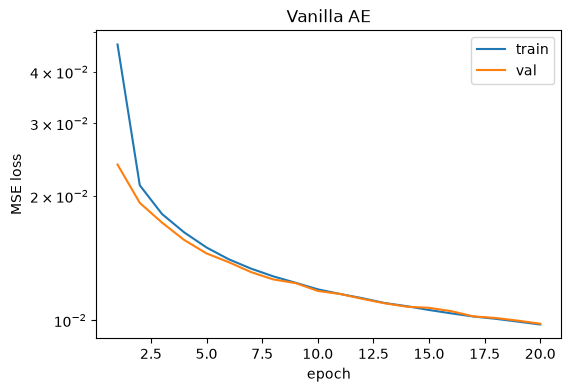

In [14]:
# loss curves 
ep = range(1, len(hist_ae["train_loss"]) + 1)
plt.figure(figsize=(6, 4))
plt.plot(ep, hist_ae["train_loss"], label="train")
plt.plot(ep, hist_ae["val_loss"], label="val")
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("MSE loss")
plt.title("Vanilla AE")
plt.legend()
plt.savefig(FIG_DIR / "ae_loss.png", dpi=300, bbox_inches="tight")
plt.show()

z_ae, _ = extract_latents(ae, test_dl) 
torch.save({"z": z_ae, "y": y_test}, CKPT_DIR / "z_ae.pt")

MLP: Step 4 part 2 (compare with AE)

In [15]:
# reconstruction metrics, AE vs MLP frozen + decoder
ae.eval()
decoder.eval()

res_ae      = recon_metrics(lambda x: ae(x)[0])
res_mlp_dec = recon_metrics(lambda x: decoder(model(x)[1]))

x64 = next(iter(test_dl))[0][:64].to(DEVICE)
lat_ae = latency_ms(lambda: ae(x64)) # encode + decode, one batch of 64
time_ae = np.mean(hist_ae["epoch_time"])

print(f"{'':16}{'MSE':>9}{'PSNR':>9}{'SSIM':>8}")
print(f"{'Vanilla AE':16}{res_ae['mse']:9.5f}{res_ae['psnr']:9.2f}{res_ae['ssim']:8.4f}")
print(f"{'MLP + decoder':16}{res_mlp_dec['mse']:9.5f}{res_mlp_dec['psnr']:9.2f}{res_mlp_dec['ssim']:8.4f}")
print(f"train time/epoch: {time_ae:.2f} s | latency: {lat_ae:.3f} ms / batch 64")

                      MSE     PSNR    SSIM
Vanilla AE        0.00969    21.05  0.8053
MLP + decoder     0.01661    18.50  0.7029
train time/epoch: 4.68 s | latency: 0.136 ms / batch 64


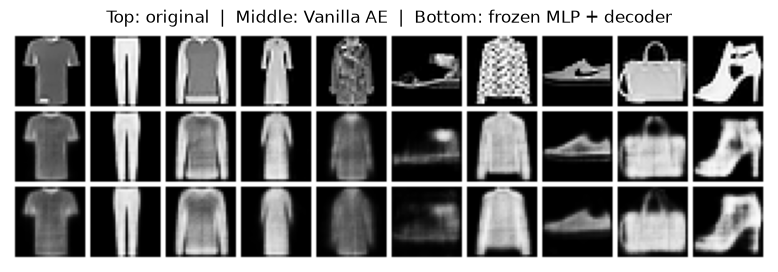

In [16]:
# one test image per class: original / Vanilla AE / MLP frozen decoder
x_all, y_all = next(iter(test_dl))
pick = [(y_all == c).nonzero()[0].item() for c in range(10)]
x_pick = x_all[pick].to(DEVICE) # (10,1,28,28)

with torch.no_grad():
    rec_ae  = ae(x_pick)[0].view(-1, 1, 28, 28)
    rec_mlp = decoder(model(x_pick)[1]).view(-1, 1, 28, 28)

show_grid(torch.cat([x_pick, rec_ae, rec_mlp]), nrow=10,
          title="Top: original  |  Middle: Vanilla AE  |  Bottom: frozen MLP + decoder",
          path=FIG_DIR / "ae_vs_mlp_recon.png")

Sparse Autoencoder 

In [17]:
def make_sae_loss(lam):
    def sae_loss(m, x, y):
        x_hat, h = m(x)
        return F.mse_loss(x_hat, x.flatten(1)) + lam * h.abs().sum(dim=1).mean()
    return sae_loss

LAMS = [1e-5, 1e-4, 1e-3]
saes, hist_sae = {}, {}
for lam in LAMS:
    set_seed(42)
    sae = AE().to(DEVICE)
    opt_sae = torch.optim.Adam(sae.parameters(), lr=1e-3)
    hist_sae[lam] = fit(f"sae_lam{lam}", sae, make_sae_loss(lam), opt_sae, train_dl, val_dl, epochs=EPOCHS)
    saes[lam] = sae 

sae_lam1e-05 ep   1 | train 0.04693 | val 0.02436 | 4.8s
sae_lam1e-05 ep   2 | train 0.02159 | val 0.01955 | 5.0s
sae_lam1e-05 ep   3 | train 0.01829 | val 0.01724 | 4.7s
sae_lam1e-05 ep   4 | train 0.01628 | val 0.01552 | 4.7s
sae_lam1e-05 ep   5 | train 0.01492 | val 0.01448 | 4.7s
sae_lam1e-05 ep   6 | train 0.01398 | val 0.01366 | 4.8s
sae_lam1e-05 ep   7 | train 0.01328 | val 0.01305 | 4.7s
sae_lam1e-05 ep   8 | train 0.01278 | val 0.01253 | 4.7s
sae_lam1e-05 ep   9 | train 0.01224 | val 0.01215 | 4.7s
sae_lam1e-05 ep  10 | train 0.01187 | val 0.01177 | 4.9s
sae_lam1e-05 ep  11 | train 0.01152 | val 0.01149 | 4.7s
sae_lam1e-05 ep  12 | train 0.01124 | val 0.01123 | 4.7s
sae_lam1e-05 ep  13 | train 0.01096 | val 0.01093 | 4.8s
sae_lam1e-05 ep  14 | train 0.01073 | val 0.01078 | 4.7s
sae_lam1e-05 ep  15 | train 0.01052 | val 0.01056 | 4.7s
sae_lam1e-05 ep  16 | train 0.01035 | val 0.01036 | 4.8s
sae_lam1e-05 ep  17 | train 0.01015 | val 0.01020 | 4.8s
sae_lam1e-05 ep  18 | train 0.0

In [18]:
models = {"AE": ae, **{f"SAE lam={lam}": saes[lam] for lam in LAMS}}

for name, m in models.items():
    h, _ = extract_latents(m, test_dl)                  # (7000, 64): the latent h
    r = recon_metrics(lambda x: m(x)[0])
    print(f"{name:16} near-zero: {(h.abs() < 1e-3).float().mean():.3f} | "
          f"MSE {r['mse']:.5f} | SSIM {r['ssim']:.4f}")

AE               near-zero: 0.392 | MSE 0.00969 | SSIM 0.8053
SAE lam=1e-05    near-zero: 0.341 | MSE 0.00920 | SSIM 0.8134
SAE lam=0.0001   near-zero: 0.559 | MSE 0.01064 | SSIM 0.7829
SAE lam=0.001    near-zero: 1.000 | MSE 0.08678 | SSIM 0.1597


In [19]:
# best = the lowest reconstruction MSE among the SAEs that are actually sparser than the vanilla AE
from src.train import eval_loss

def val_sparsity(m):
    h, _ = extract_latents(m, val_dl)              # (7000, 64)
    return (h.abs() < 1e-3).float().mean().item()  # fraction of near-zero latent units

ae_sparsity = val_sparsity(ae)
val_res = {lam: (eval_loss(saes[lam], ae_loss, val_dl), val_sparsity(saes[lam])) for lam in LAMS}
for lam, (mse, sp) in val_res.items():
    print(f"lam={lam:<7} val MSE {mse:.5f} | near-zero {sp:.3f}")

sparser = [lam for lam in LAMS if val_res[lam][1] > ae_sparsity] or LAMS
best_lam = min(sparser, key=lambda lam: val_res[lam][0])
sae_best = saes[best_lam]
print(f"vanilla AE near-zero {ae_sparsity:.3f} -> best lam = {best_lam}")

lam=1e-05   val MSE 0.00932 | near-zero 0.341
lam=0.0001  val MSE 0.01080 | near-zero 0.559
lam=0.001   val MSE 0.08713 | near-zero 1.000
vanilla AE near-zero 0.391 -> best lam = 0.0001


Variational Autoencoder (VAE) 

In [20]:
class VAE(nn.Module):
    def __init__(self, z_dim=64):
        super().__init__()
        self.body = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU())
        self.mu = nn.Linear(256, z_dim)
        self.logvar = nn.Linear(256, z_dim)
        self.dec = nn.Sequential(nn.Linear(z_dim, 256), nn.ReLU(),
                                 nn.Linear(256, 784), nn.Sigmoid())
    def encode(self, x):
        h = self.body(x)
        return self.mu(h), self.logvar(h)
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)   # reparameterisation trick
        return self.dec(z), mu, logvar

def vae_loss(m, x, y):
    x_hat, mu, logvar = m(x)
    B = x.size(0)
    rec = F.binary_cross_entropy(x_hat, x.flatten(1), reduction="sum") / B
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / B
    return rec + kl

In [21]:
set_seed(42)
vae = VAE().to(DEVICE)
opt_vae = torch.optim.Adam(vae.parameters(), lr=1e-3)
print("parameters:", sum(p.numel() for p in vae.parameters()))

# train and validate
hist_vae = fit("vae", vae, vae_loss, opt_vae, train_dl, val_dl, epochs=EPOCHS)

parameters: 451984
vae ep   1 | train 318.61269 | val 280.50254 | 5.1s
vae ep   2 | train 274.83316 | val 270.99767 | 4.9s
vae ep   3 | train 266.96308 | val 264.24628 | 4.9s
vae ep   4 | train 261.18543 | val 259.39870 | 4.8s
vae ep   5 | train 256.89719 | val 256.05329 | 5.0s
vae ep   6 | train 253.85229 | val 253.42965 | 4.8s
vae ep   7 | train 251.58641 | val 251.60127 | 4.9s
vae ep   8 | train 249.92891 | val 249.84121 | 5.0s
vae ep   9 | train 248.56994 | val 248.79730 | 4.9s
vae ep  10 | train 247.55934 | val 247.73222 | 4.9s
vae ep  11 | train 246.79930 | val 247.38420 | 4.9s
vae ep  12 | train 246.09636 | val 246.72066 | 4.9s
vae ep  13 | train 245.59622 | val 246.19472 | 4.8s
vae ep  14 | train 245.07300 | val 245.60809 | 4.8s
vae ep  15 | train 244.71074 | val 245.71069 | 4.9s
vae ep  16 | train 244.35159 | val 245.12664 | 4.8s
vae ep  17 | train 244.09288 | val 244.72090 | 4.8s
vae ep  18 | train 243.78904 | val 244.53520 | 4.9s
vae ep  19 | train 243.57833 | val 244.26760 

class              AE      SAE      VAE
T-shirt/top   0.00371  0.00474  0.00563
Trouser       0.00188  0.00178  0.00289
Pullover      0.00721  0.01004  0.01306
Dress         0.00663  0.00864  0.01099
Coat          0.01028  0.01071  0.01116
Sandal        0.01017  0.01046  0.01793
Shirt         0.03247  0.03421  0.03588
Sneaker       0.00610  0.00646  0.00918
Bag           0.01780  0.02069  0.02140
Ankle boot    0.02410  0.02986  0.03811


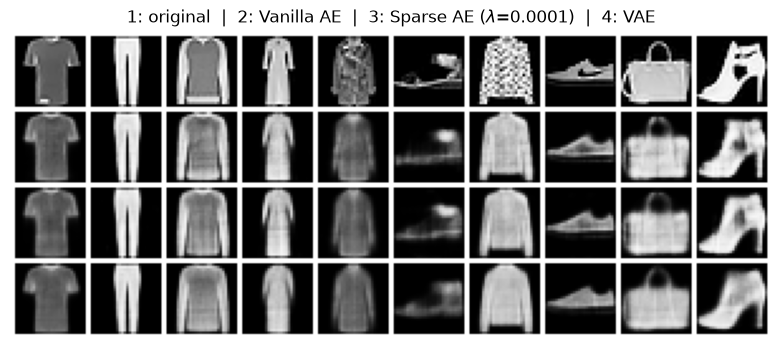

In [22]:
x_all, y_all = next(iter(test_dl))                       # shuffle=False -> same images every run
pick = [(y_all == c).nonzero()[0].item() for c in range(10)]
x_pick = x_all[pick].to(DEVICE)                          # (10,1,28,28)

ae.eval()
sae_best.eval()
vae.eval()
with torch.no_grad():
    rec_ae  = ae(x_pick)[0].view(-1, 1, 28, 28)
    rec_sae = sae_best(x_pick)[0].view(-1, 1, 28, 28)
    rec_vae = vae.dec(vae.encode(x_pick)[0]).view(-1, 1, 28, 28)  # z = mu: vae(x) would add random noise

mse_ae  = ((rec_ae  - x_pick) ** 2).flatten(1).mean(1)
mse_sae = ((rec_sae - x_pick) ** 2).flatten(1).mean(1)
mse_vae = ((rec_vae - x_pick) ** 2).flatten(1).mean(1)
print(f"{'class':12}{'AE':>9}{'SAE':>9}{'VAE':>9}")
for c in range(10):
    print(f"{CLASSES[c]:12}{mse_ae[c]:9.5f}{mse_sae[c]:9.5f}{mse_vae[c]:9.5f}")

show_grid(torch.cat([x_pick, rec_ae, rec_sae, rec_vae]), nrow=10,
          title=f"1: original  |  2: Vanilla AE  |  3: Sparse AE ($\\lambda$={best_lam})  |  4: VAE",
          path=FIG_DIR / "ae_sae_vae_recon.png")

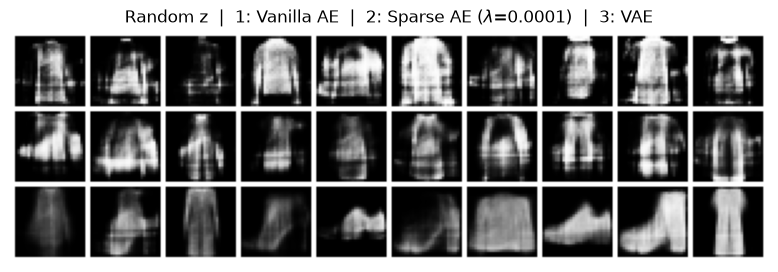

In [23]:
# decode RANDOM latents
def fitted_gaussian(m):
    z, _ = extract_latents(m, test_dl)   # (7000, 64)
    return z.mean(0), z.std(0)           # per-dimension mean and std, (64,) each

mu_ae,  sd_ae  = fitted_gaussian(ae)
mu_sae, sd_sae = fitted_gaussian(sae_best)

set_seed(42)
with torch.no_grad():
    smp_ae  = ae.dec((mu_ae + sd_ae * torch.randn(10, 64)).to(DEVICE)).view(-1, 1, 28, 28)
    smp_sae = sae_best.dec((mu_sae + sd_sae * torch.randn(10, 64)).to(DEVICE)).view(-1, 1, 28, 28)
    smp_vae = vae.dec(torch.randn(10, 64, device=DEVICE)).view(-1, 1, 28, 28)

show_grid(torch.cat([smp_ae, smp_sae, smp_vae]), nrow=10,
          title=f"Random z  |  1: Vanilla AE  |  2: Sparse AE ($\\lambda$={best_lam})  |  3: VAE",
          path=FIG_DIR / "ae_sae_vae_samples.png")

Generative Adversarial Network (GAN) 

In [24]:
# Generator: noise z (100) -> 256 -> 512 -> 1024 -> 784 pixels
class G_MLP(nn.Module):
    def __init__(self, z_dim=100):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 1024), nn.LeakyReLU(0.2),
            nn.Linear(1024, 784), nn.Tanh())
    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)

# Discriminator: image (784) -> 512 -> 256 -> 1 (riyal or fake)
class D_MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 1)) # raw logit: BCEWithLogitsLoss adds the sigmoid
    def forward(self, x):
        return self.net(x)

Z_DIM = 100          # noise size, shared with the DCGAN
GAN_EPOCHS = 50      # GANs need more epochs than the AE family

# loss using BCEWithLogits in train.py

In [25]:
from src.train import train_gan

set_seed(42)
G_gan = G_MLP(Z_DIM).to(DEVICE)
D_gan = D_MLP().to(DEVICE)
print("G parameters:", sum(p.numel() for p in G_gan.parameters()))
print("D parameters:", sum(p.numel() for p in D_gan.parameters()))

# samples of the same 64 noise vectors go to outputs/samples/gan_epXXX.png
hist_gan = train_gan("gan", G_gan, D_gan, train_dl, epochs=GAN_EPOCHS, z_dim=Z_DIM)

G parameters: 1486352
D parameters: 533505
gan ep   1 | D 1.002 | G 0.893 | D(x) 0.81 | D(G(z)) 0.42 | 4.4s
gan ep   2 | D 0.864 | G 1.440 | D(x) 0.80 | D(G(z)) 0.24 | 4.7s
gan ep   3 | D 0.846 | G 1.838 | D(x) 0.75 | D(G(z)) 0.18 | 4.9s
gan ep   4 | D 0.938 | G 1.895 | D(x) 0.69 | D(G(z)) 0.18 | 5.0s
gan ep   5 | D 0.848 | G 2.220 | D(x) 0.72 | D(G(z)) 0.14 | 5.0s
gan ep   6 | D 0.876 | G 2.062 | D(x) 0.71 | D(G(z)) 0.16 | 5.0s
gan ep   7 | D 0.921 | G 1.907 | D(x) 0.69 | D(G(z)) 0.18 | 5.0s
gan ep   8 | D 1.028 | G 1.691 | D(x) 0.66 | D(G(z)) 0.22 | 4.9s
gan ep   9 | D 0.988 | G 1.625 | D(x) 0.66 | D(G(z)) 0.23 | 4.9s
gan ep  10 | D 1.022 | G 1.567 | D(x) 0.66 | D(G(z)) 0.24 | 4.9s
gan ep  11 | D 1.075 | G 1.427 | D(x) 0.63 | D(G(z)) 0.27 | 5.1s
gan ep  12 | D 1.087 | G 1.399 | D(x) 0.63 | D(G(z)) 0.28 | 5.0s
gan ep  13 | D 1.096 | G 1.326 | D(x) 0.62 | D(G(z)) 0.29 | 5.0s
gan ep  14 | D 1.144 | G 1.349 | D(x) 0.61 | D(G(z)) 0.29 | 5.1s
gan ep  15 | D 1.136 | G 1.279 | D(x) 0.60 | D(

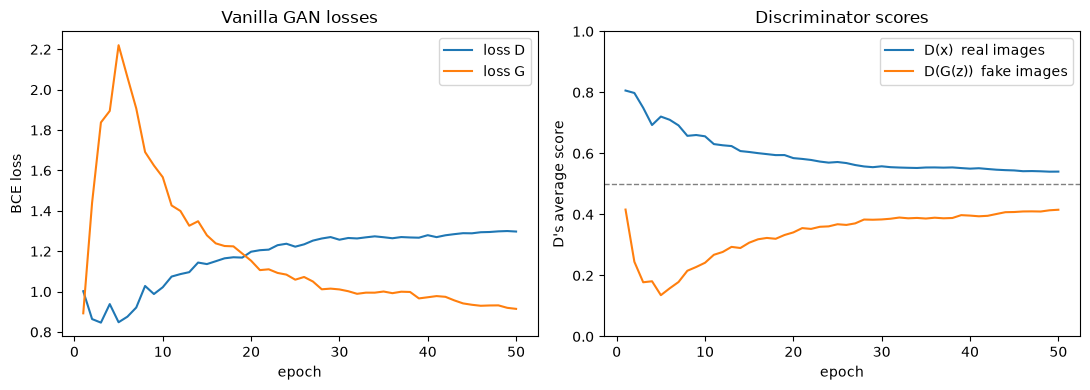

In [26]:
# training curves
# left: the two losses fight each other; right: D's average "real" score for real vs fake images
ep = range(1, len(hist_gan["loss_D"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(ep, hist_gan["loss_D"], label="loss D")
ax1.plot(ep, hist_gan["loss_G"], label="loss G")
ax1.set_xlabel("epoch"); ax1.set_ylabel("BCE loss"); ax1.set_title("Vanilla GAN losses"); ax1.legend()

ax2.plot(ep, hist_gan["D_real"], label="D(x)  real images")
ax2.plot(ep, hist_gan["D_fake"], label="D(G(z))  fake images")
ax2.axhline(0.5, color="gray", ls="--", lw=1)         # 0.5 = D can't tell real from fake (ideal end point)
ax2.set_ylim(0, 1)
ax2.set_xlabel("epoch"); ax2.set_ylabel("D's average score"); ax2.set_title("Discriminator scores"); ax2.legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "gan_loss.png", dpi=300, bbox_inches="tight")
plt.show()

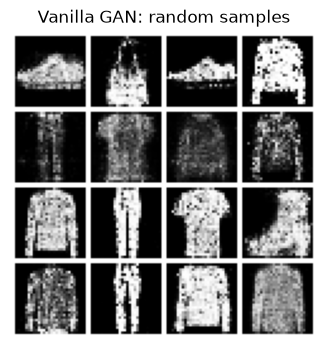

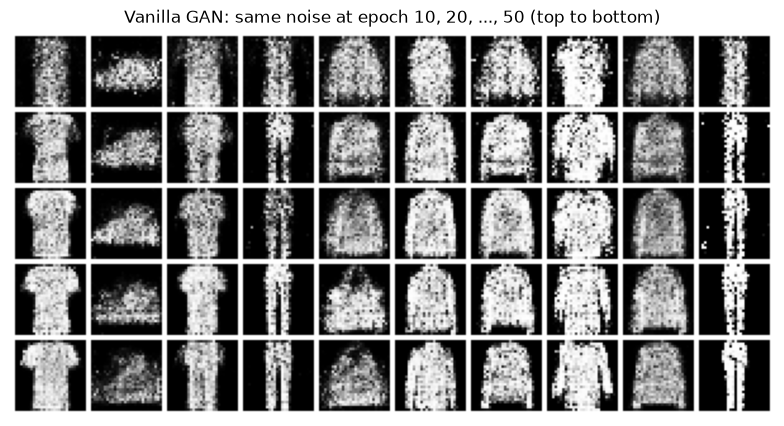

train time/epoch: 4.99 s | latency: 1.056 ms / batch 64


In [27]:
# 16 random samples from the final G (Figure 2 panel), fixed seed so the figure is reproducible
G_gan.eval()
set_seed(42)
with torch.no_grad():
    smp_gan = (G_gan(torch.randn(16, Z_DIM, device=DEVICE)) + 1) / 2   # [-1,1] -> [0,1] for display/metrics
show_grid(smp_gan, nrow=4, title="Vanilla GAN: random samples", path=FIG_DIR / "gan_samples.png")

# training progress: the SAME 10 noise vectors decoded by G at epoch 10, 20, ..., 50 (top to bottom)
set_seed(0)
z_prog = torch.randn(10, Z_DIM, device=DEVICE)
G_tmp = G_MLP(Z_DIM).to(DEVICE).eval()
rows = []
for e in range(10, GAN_EPOCHS + 1, 10):
    G_tmp.load_state_dict(torch.load(CKPT_DIR / f"gan_G_ep{e}.pt", map_location=DEVICE))
    with torch.no_grad():
        rows.append((G_tmp(z_prog) + 1) / 2)
show_grid(torch.cat(rows), nrow=10, title="Vanilla GAN: same noise at epoch 10, 20, ..., 50 (top to bottom)",
          path=FIG_DIR / "gan_progress.png")

# train time/epoch and latency
z64 = torch.randn(64, Z_DIM, device=DEVICE)
lat_gan = latency_ms(lambda: G_gan(z64))
time_gan = np.mean(hist_gan["epoch_time"])
print(f"train time/epoch: {time_gan:.2f} s | latency: {lat_gan:.3f} ms / batch 64")

In [28]:
# mode-collapse check: let the trained MLP classifier label 5,000 GAN samples
set_seed(42)
with torch.no_grad():
    fake = torch.cat([(G_gan(torch.randn(500, Z_DIM, device=DEVICE)) + 1) / 2 for _ in range(10)])
    pred = model(fake)[0].argmax(1).cpu()
share = torch.bincount(pred, minlength=10).float() / len(pred)

for c in range(10):
    print(f"{CLASSES[c]:12} {share[c]:6.1%}  " + "#" * int(share[c] * 100))

T-shirt/top   14.6%  ##############
Trouser        9.2%  #########
Pullover      12.2%  ############
Dress         11.2%  ###########
Coat           6.0%  #####
Sandal         6.8%  ######
Shirt         13.8%  #############
Sneaker        9.3%  #########
Bag            8.7%  ########
Ankle boot     8.2%  ########


Deep Convolutional GAN (DCGAN) 

In [29]:
# Generator: noise z (100) -> 128 maps of 7x7 -> 64 maps of 14x14 -> 1 image of 28x28 in [-1, 1]
class G_DC(nn.Module):
    def __init__(self, z_dim=100, ch=64):
        super().__init__()
        self.ch = ch
        self.fc = nn.Sequential(
            nn.Linear(z_dim, ch * 2 * 7 * 7), nn.BatchNorm1d(ch * 2 * 7 * 7), nn.ReLU())
        self.net = nn.Sequential(
            nn.ConvTranspose2d(ch * 2, ch, 4, 2, 1), nn.BatchNorm2d(ch), nn.ReLU(),   # 7x7   -> 14x14
            nn.ConvTranspose2d(ch, 1, 4, 2, 1), nn.Tanh())                           # 14x14 -> 28x28
    def forward(self, z):
        return self.net(self.fc(z).view(-1, self.ch * 2, 7, 7))

# Discriminator: image 28x28 -> 64 maps of 14x14 -> 128 maps of 7x7 -> 1 score (raw logit)
class D_DC(nn.Module):
    def __init__(self, ch=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, ch, 4, 2, 1), nn.LeakyReLU(0.2),                              # 28x28 -> 14x14 (no BN on input layer)
            nn.Conv2d(ch, ch * 2, 4, 2, 1), nn.BatchNorm2d(ch * 2), nn.LeakyReLU(0.2), # 14x14 -> 7x7
            nn.Flatten(), nn.Linear(ch * 2 * 7 * 7, 1))
    def forward(self, x):
        return self.net(x)

print(G_DC(Z_DIM)(torch.randn(2, Z_DIM)).shape)        # (2, 1, 28, 28)
print(D_DC()(torch.randn(2, 1, 28, 28)).shape)         # (2, 1)

torch.Size([2, 1, 28, 28])
torch.Size([2, 1])


In [30]:
# train
set_seed(42)
G_dc = G_DC(Z_DIM).to(DEVICE)
D_dc = D_DC().to(DEVICE)
print("G parameters:", sum(p.numel() for p in G_dc.parameters()))
print("D parameters:", sum(p.numel() for p in D_dc.parameters()))

# samples of the same 64 noise vectors go to outputs/samples/dcgan_epXXX.png
hist_dc = train_gan("dcgan", G_dc, D_dc, train_dl, epochs=GAN_EPOCHS, z_dim=Z_DIM)

G parameters: 778305
D parameters: 138817
dcgan ep   1 | D 0.385 | G 2.477 | D(x) 0.85 | D(G(z)) 0.13 | 9.1s
dcgan ep   2 | D 0.301 | G 2.497 | D(x) 0.87 | D(G(z)) 0.11 | 8.8s
dcgan ep   3 | D 0.340 | G 2.584 | D(x) 0.86 | D(G(z)) 0.12 | 8.8s
dcgan ep   4 | D 0.350 | G 2.403 | D(x) 0.86 | D(G(z)) 0.13 | 8.8s
dcgan ep   5 | D 0.384 | G 2.374 | D(x) 0.84 | D(G(z)) 0.15 | 8.8s
dcgan ep   6 | D 0.501 | G 2.139 | D(x) 0.81 | D(G(z)) 0.18 | 8.8s
dcgan ep   7 | D 0.541 | G 1.976 | D(x) 0.79 | D(G(z)) 0.19 | 8.9s
dcgan ep   8 | D 0.566 | G 1.915 | D(x) 0.78 | D(G(z)) 0.20 | 8.8s
dcgan ep   9 | D 0.595 | G 1.865 | D(x) 0.77 | D(G(z)) 0.21 | 8.8s
dcgan ep  10 | D 0.614 | G 1.831 | D(x) 0.77 | D(G(z)) 0.22 | 8.8s
dcgan ep  11 | D 0.617 | G 1.828 | D(x) 0.77 | D(G(z)) 0.22 | 8.8s
dcgan ep  12 | D 0.627 | G 1.819 | D(x) 0.76 | D(G(z)) 0.22 | 8.9s
dcgan ep  13 | D 0.616 | G 1.827 | D(x) 0.77 | D(G(z)) 0.22 | 8.8s
dcgan ep  14 | D 0.620 | G 1.855 | D(x) 0.77 | D(G(z)) 0.22 | 8.8s
dcgan ep  15 | D 0.6

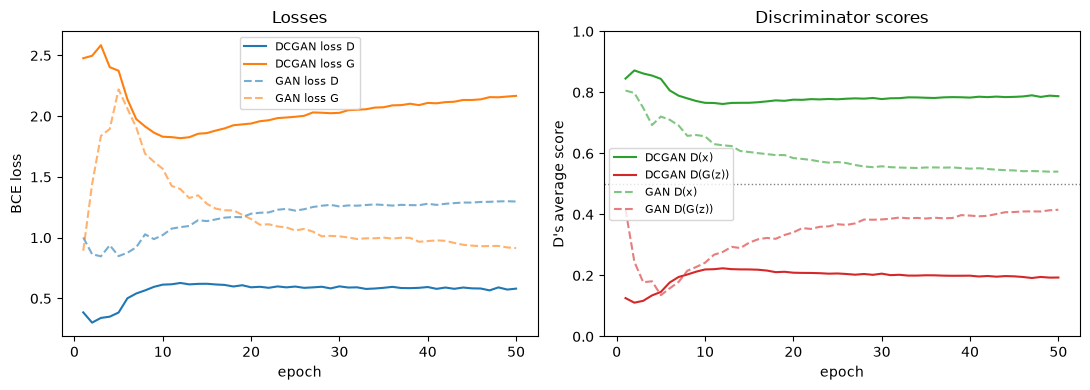

In [31]:
# training curves: DCGAN and Vanilla GAN
ep    = range(1, len(hist_dc["loss_D"]) + 1)
ep_gan = range(1, len(hist_gan["loss_D"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(ep, hist_dc["loss_D"], color="C0", label="DCGAN loss D")
ax1.plot(ep, hist_dc["loss_G"], color="C1", label="DCGAN loss G")
ax1.plot(ep_gan, hist_gan["loss_D"], color="C0", ls="--", alpha=0.6, label="GAN loss D")
ax1.plot(ep_gan, hist_gan["loss_G"], color="C1", ls="--", alpha=0.6, label="GAN loss G")
ax1.set_xlabel("epoch"); ax1.set_ylabel("BCE loss"); ax1.set_title("Losses"); ax1.legend(fontsize=8)

ax2.plot(ep, hist_dc["D_real"], color="C2", label="DCGAN D(x)")
ax2.plot(ep, hist_dc["D_fake"], color="C3", label="DCGAN D(G(z))")
ax2.plot(ep_gan, hist_gan["D_real"], color="C2", ls="--", alpha=0.6, label="GAN D(x)")
ax2.plot(ep_gan, hist_gan["D_fake"], color="C3", ls="--", alpha=0.6, label="GAN D(G(z))")
ax2.axhline(0.5, color="gray", ls=":", lw=1)            # 0.5 = D can't tell real from fake
ax2.set_ylim(0, 1)
ax2.set_xlabel("epoch"); ax2.set_ylabel("D's average score"); ax2.set_title("Discriminator scores"); ax2.legend(fontsize=8)

plt.tight_layout()
plt.savefig(FIG_DIR / "dcgan_loss.png", dpi=300, bbox_inches="tight")
plt.show()

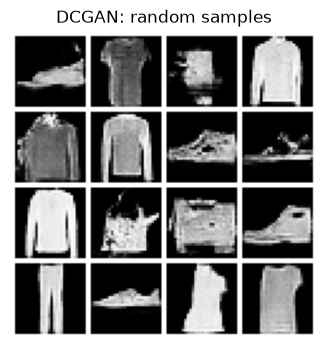

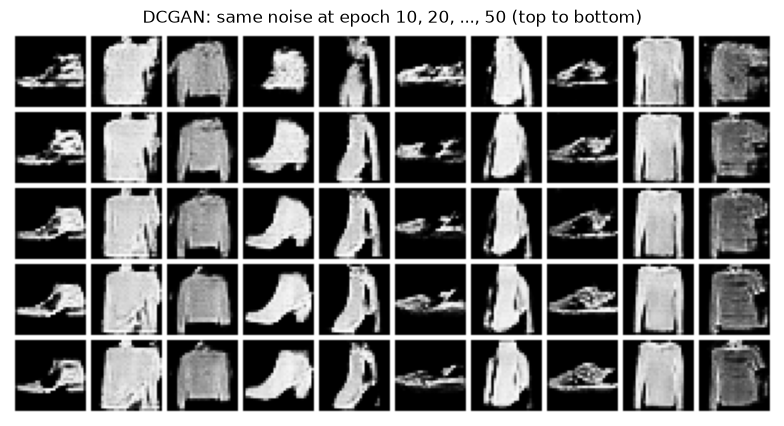

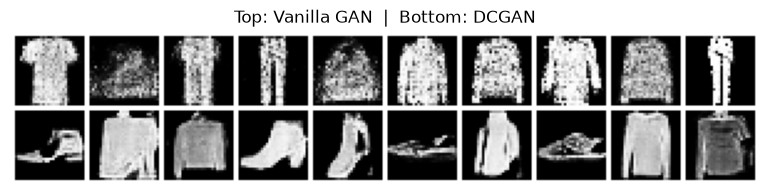

              time/epoch (s)  latency (ms/64)
Vanilla GAN             4.99            1.056
DCGAN                   8.85            2.890


In [32]:
# 16 random samples from the final G
G_dc.eval()
set_seed(42)
with torch.no_grad():
    smp_dc = (G_dc(torch.randn(16, Z_DIM, device=DEVICE)) + 1) / 2   # [-1,1] -> [0,1]
show_grid(smp_dc, nrow=4, title="DCGAN: random samples", path=FIG_DIR / "dcgan_samples.png")

# training progress: the same 10 noise vectors at epoch 10, 20, ..., 50
G_tmp = G_DC(Z_DIM).to(DEVICE).eval()
rows = []
for e in range(10, GAN_EPOCHS + 1, 10):
    G_tmp.load_state_dict(torch.load(CKPT_DIR / f"dcgan_G_ep{e}.pt", map_location=DEVICE))
    with torch.no_grad():
        rows.append((G_tmp(z_prog) + 1) / 2)
show_grid(torch.cat(rows), nrow=10, title="DCGAN: same noise at epoch 10, 20, ..., 50 (top to bottom)",
          path=FIG_DIR / "dcgan_progress.png")

# GAN vs DCGAN, 10 samples each from the same noise vectors
with torch.no_grad():
    row_gan = (G_gan(z_prog) + 1) / 2
    row_dc  = (G_dc(z_prog) + 1) / 2
show_grid(torch.cat([row_gan, row_dc]), nrow=10, title="Top: Vanilla GAN  |  Bottom: DCGAN",
          path=FIG_DIR / "gan_vs_dcgan.png")

# train time/epoch and latency
lat_dc = latency_ms(lambda: G_dc(z64))
time_dc = np.mean(hist_dc["epoch_time"])
print(f"{'':12}{'time/epoch (s)':>16}{'latency (ms/64)':>17}")
print(f"{'Vanilla GAN':12}{time_gan:16.2f}{lat_gan:17.3f}")
print(f"{'DCGAN':12}{time_dc:16.2f}{lat_dc:17.3f}")

In [33]:
# mode-collapse check, GAN vs DCGAN: the MLP classifier labels 5,000 samples from each generator
def class_share(G, n=5000, batch=500):
    G.eval()
    set_seed(42)
    with torch.no_grad():
        fake = torch.cat([(G(torch.randn(batch, Z_DIM, device=DEVICE)) + 1) / 2 for _ in range(n // batch)])
        pred = model(fake)[0].argmax(1).cpu()
    return torch.bincount(pred, minlength=10).float() / len(pred)

share_gan, share_dc = class_share(G_gan), class_share(G_dc)
print(f"{'class':12}{'GAN':>8}{'DCGAN':>8}")
for c in range(10):
    print(f"{CLASSES[c]:12}{share_gan[c]:8.1%}{share_dc[c]:8.1%}")
print(f"{'max - min':12}{share_gan.max() - share_gan.min():8.1%}{share_dc.max() - share_dc.min():8.1%}")

class            GAN   DCGAN
T-shirt/top    14.6%   10.4%
Trouser         9.2%   10.3%
Pullover       12.2%   11.0%
Dress          11.2%    9.9%
Coat            6.0%    9.8%
Sandal          6.8%   11.0%
Shirt          13.8%    7.6%
Sneaker         9.3%    9.0%
Bag             8.7%   11.2%
Ankle boot      8.2%    9.8%
max - min       8.6%    3.5%


Denoising Diffusion Probabilistic Models (DDPM)

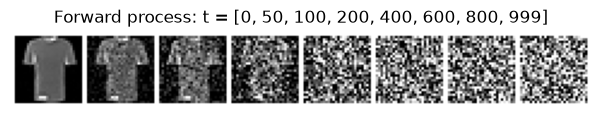

share of the clean image left, sqrt(abar_t): [1.0, 0.985, 0.946, 0.81, 0.44, 0.16, 0.039, 0.006]


In [34]:
# noise schedule: a fixed table, not learned. Each step t adds a little Gaussian noise (beta_t);
# abar_t = alpha_1 * alpha_2 * ... * alpha_t says how much of the clean image is left after t steps
T = 1000
betas = torch.linspace(1e-4, 0.02, T, device=DEVICE)
alphas = 1 - betas
abar = torch.cumprod(alphas, dim=0)

def q_sample(x0, t, eps):
    """Forward process: jump straight to step t by mixing the clean image x0 with noise eps."""
    a = abar[t].view(-1, 1, 1, 1)
    return a.sqrt() * x0 + (1 - a).sqrt() * eps

# what the forward process does to one test image (left = clean, right = pure noise)
steps = [0, 50, 100, 200, 400, 600, 800, 999]
x0 = (x_pick[:1] * 2 - 1).repeat(len(steps), 1, 1, 1)     # the T-shirt from the AE comparison, in [-1, 1]
set_seed(42)
xt = q_sample(x0, torch.tensor(steps, device=DEVICE), torch.randn_like(x0))
show_grid((xt.clamp(-1, 1) + 1) / 2, nrow=len(steps), title=f"Forward process: t = {steps}",
          path=FIG_DIR / "ddpm_forward.png")
print("share of the clean image left, sqrt(abar_t):", [round(abar[s].sqrt().item(), 3) for s in steps])

In [ ]:
import math

class TimeEmb(nn.Module):
    """Turns the integer t into a vector of sines and cosines (like Transformer positional encoding)."""
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
    def forward(self, t):
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
        args = t[:, None].float() * freqs[None]
        return torch.cat([args.sin(), args.cos()], dim=1)          # (B, dim)

class Block(nn.Module):
    """Two 3x3 convs with GroupNorm + SiLU, the step embedding added in between, plus a residual skip."""
    def __init__(self, cin, cout, tdim):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, 3, padding=1); self.n1 = nn.GroupNorm(8, cout)
        self.c2 = nn.Conv2d(cout, cout, 3, padding=1); self.n2 = nn.GroupNorm(8, cout)
        self.t = nn.Linear(tdim, cout)
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
    def forward(self, x, temb):
        h = F.silu(self.n1(self.c1(x)))
        h = h + self.t(temb)[:, :, None, None]                     # inject "which step" into every pixel
        h = F.silu(self.n2(self.c2(h)))
        return h + self.skip(x)                                    # residual connection

# U-Net: go down to 7x7 to see the whole garment, come back up to 28x28, and copy the fine detail
# across with skip connections (torch.cat). Output = the predicted noise, same shape as the input
class TinyUNet(nn.Module):
    def __init__(self, ch=64, tdim=128):
        super().__init__()
        self.temb = nn.Sequential(TimeEmb(tdim), nn.Linear(tdim, tdim), nn.SiLU(), nn.Linear(tdim, tdim))
        self.inc = nn.Conv2d(1, ch, 3, padding=1)
        self.d1 = Block(ch, ch, tdim)              # 28x28
        self.d2 = Block(ch, ch * 2, tdim)          # 14x14
        self.mid = Block(ch * 2, ch * 2, tdim)     # 7x7
        self.u2 = Block(ch * 4, ch * 2, tdim)      # 14x14 (input = upsampled mid + skip from d2)
        self.u1 = Block(ch * 3, ch, tdim)          # 28x28 (input = upsampled u2 + skip from d1)
        self.out = nn.Conv2d(ch, 1, 1)
        self.pool = nn.AvgPool2d(2)
        self.up = nn.Upsample(scale_factor=2, mode="nearest")
    def forward(self, x, t):
        te = self.temb(t)
        d1 = self.d1(self.inc(x), te)
        d2 = self.d2(self.pool(d1), te)
        m = self.mid(self.pool(d2), te)
        u2 = self.u2(torch.cat([self.up(m), d2], dim=1), te)
        u1 = self.u1(torch.cat([self.up(u2), d1], dim=1), te)
        return self.out(u1)

print(TinyUNet()(torch.randn(2, 1, 28, 28), torch.tensor([0, 999])).shape)   # (2, 1, 28, 28)

torch.Size([2, 1, 28, 28])


In [ ]:
# training: noise each clean image to a random step t and ask the network to predict the noise that was added. It is a plain MSE, so fit() works unchanged
def ddpm_loss(m, x, y):
    x0 = x * 2 - 1                                          # [0,1] -> [-1,1]
    t = torch.randint(0, T, (x0.size(0),), device=DEVICE)   # a different random step for every image
    eps = torch.randn_like(x0)
    return F.mse_loss(m(q_sample(x0, t, eps), t), eps)

DDPM_EPOCHS = 30

set_seed(42)
unet = TinyUNet().to(DEVICE)
opt_unet = torch.optim.Adam(unet.parameters(), lr=2e-4)
print("parameters:", sum(p.numel() for p in unet.parameters()))

# the val loss is noisy because t is random every time: that is expected
hist_ddpm = fit("ddpm", unet, ddpm_loss, opt_unet, train_dl, val_dl, epochs=DDPM_EPOCHS)

parameters: 1336065
ddpm ep   1 | train 0.15113 | val 0.07432 | 56.7s
ddpm ep   2 | train 0.06782 | val 0.06347 | 56.5s
ddpm ep   3 | train 0.05874 | val 0.05681 | 56.3s
ddpm ep   4 | train 0.05450 | val 0.05339 | 56.5s
ddpm ep   5 | train 0.05109 | val 0.05163 | 56.5s
ddpm ep   6 | train 0.05018 | val 0.05200 | 56.2s
ddpm ep   7 | train 0.04881 | val 0.04561 | 56.9s
ddpm ep   8 | train 0.04729 | val 0.04480 | 56.7s
ddpm ep   9 | train 0.04756 | val 0.04586 | 57.0s
ddpm ep  10 | train 0.04527 | val 0.04554 | 56.6s
ddpm ep  11 | train 0.04520 | val 0.04496 | 56.7s
ddpm ep  12 | train 0.04454 | val 0.04449 | 56.7s
ddpm ep  13 | train 0.04351 | val 0.04329 | 57.0s
ddpm ep  14 | train 0.04401 | val 0.04345 | 56.7s
ddpm ep  15 | train 0.04273 | val 0.04274 | 56.7s
ddpm ep  16 | train 0.04253 | val 0.04198 | 56.8s
ddpm ep  17 | train 0.04278 | val 0.04162 | 57.4s
ddpm ep  18 | train 0.04251 | val 0.04275 | 57.2s
ddpm ep  19 | train 0.04250 | val 0.04245 | 57.2s
ddpm ep  20 | train 0.04180 | 

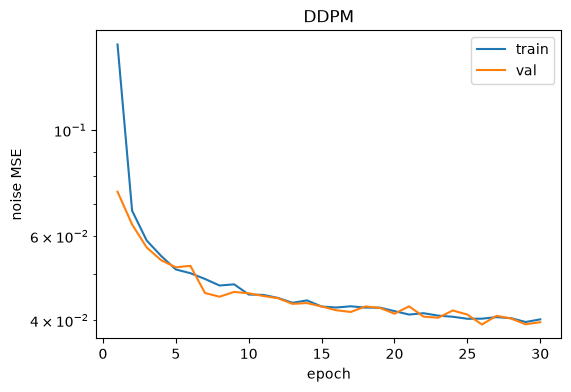

In [37]:
# loss curve
ep = range(1, len(hist_ddpm["train_loss"]) + 1)
plt.figure(figsize=(6, 4))
plt.plot(ep, hist_ddpm["train_loss"], label="train")
plt.plot(ep, hist_ddpm["val_loss"], label="val")
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("noise MSE")
plt.title("DDPM")
plt.legend()
plt.savefig(FIG_DIR / "ddpm_loss.png", dpi=300, bbox_inches="tight")
plt.show()

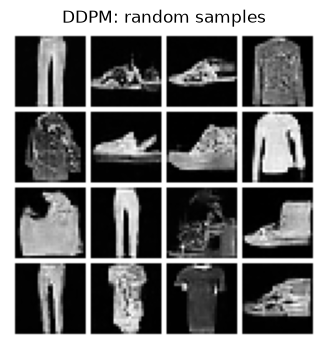

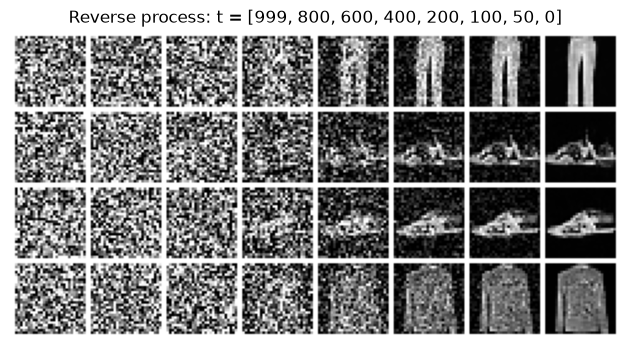

train time/epoch: 56.93 s | latency: 22303 ms / batch 64 (7717x the DCGAN)


In [ ]:
# sampling: start from pure noise and remove a little noise 1,000 times
@torch.no_grad()
def ddpm_sample(m, n, save_at=(999, 800, 600, 400, 200, 100, 50, 0)):
    m.eval()
    x = torch.randn(n, 1, 28, 28, device=DEVICE)            # x_T: pure noise
    traj = {}
    for i in reversed(range(T)):
        t = torch.full((n,), i, device=DEVICE, dtype=torch.long)
        eps_hat = m(x, t)                                    # the network's guess of the noise in x
        mean = (x - betas[i] / (1 - abar[i]).sqrt() * eps_hat) / alphas[i].sqrt()
        x = mean + betas[i].sqrt() * torch.randn_like(x) if i > 0 else mean   # no noise on the last step
        if i in save_at:
            traj[i] = ((x.clamp(-1, 1) + 1) / 2).cpu()
    return (x.clamp(-1, 1) + 1) / 2, traj                   # back to [0, 1]

# 16 random samples
set_seed(42)
smp_ddpm, traj = ddpm_sample(unet, 16)
show_grid(smp_ddpm, nrow=4, title="DDPM: random samples", path=FIG_DIR / "ddpm_samples.png")

# denoising trajectory: each row is one sample, from pure noise (left) to the image (right)
order = sorted(traj, reverse=True)
grid = torch.stack([traj[i][:4] for i in order], dim=1).flatten(0, 1)   # (4 samples x 8 steps, 1, 28, 28)
show_grid(grid, nrow=len(order), title=f"Reverse process: t = {order}", path=FIG_DIR / "ddpm_trajectory.png")

# numbers for the comparison table: the FULL 1,000-step sampling of 64 images (slow, so only 2 repeats)
lat_ddpm = latency_ms(lambda: ddpm_sample(unet, 64), reps=2, warmup=1)
time_ddpm = np.mean(hist_ddpm["epoch_time"])
print(f"train time/epoch: {time_ddpm:.2f} s | latency: {lat_ddpm:.0f} ms / batch 64 "
      f"({lat_ddpm / lat_dc:.0f}x the DCGAN)")

In [39]:
# mode coverage: the MLP classifier labels 1,000 DDPM samples (fewer than the GANs' 5,000: sampling is slow)
set_seed(42)
fake_ddpm = torch.cat([ddpm_sample(unet, 500)[0] for _ in range(2)])
with torch.no_grad():
    pred = model(fake_ddpm.to(DEVICE))[0].argmax(1).cpu()
share_ddpm = torch.bincount(pred, minlength=10).float() / len(pred)

print(f"{'class':12}{'GAN':>8}{'DCGAN':>8}{'DDPM':>8}")
for c in range(10):
    print(f"{CLASSES[c]:12}{share_gan[c]:8.1%}{share_dc[c]:8.1%}{share_ddpm[c]:8.1%}")
spread = lambda s: s.max() - s.min()
print(f"{'max - min':12}{spread(share_gan):8.1%}{spread(share_dc):8.1%}{spread(share_ddpm):8.1%}  (smaller = more even)")

class            GAN   DCGAN    DDPM
T-shirt/top    14.6%   10.4%    7.8%
Trouser         9.2%   10.3%   15.0%
Pullover       12.2%   11.0%   10.0%
Dress          11.2%    9.9%   11.1%
Coat            6.0%    9.8%    7.7%
Sandal          6.8%   11.0%   12.5%
Shirt          13.8%    7.6%    8.3%
Sneaker         9.3%    9.0%   11.2%
Bag             8.7%   11.2%    6.1%
Ankle boot      8.2%    9.8%   10.3%
max - min       8.6%    3.5%    8.9%  (smaller = more even)


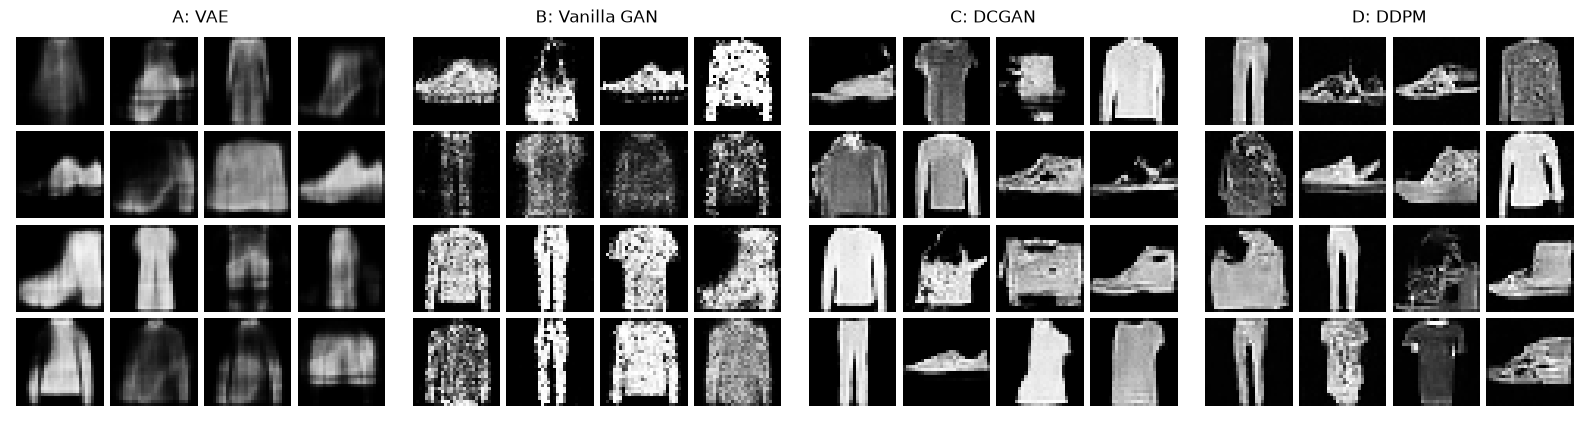

In [ ]:
# 16 random samples from each generative model, side by side (all drawn with seed 42)
from torchvision.utils import make_grid

vae.eval()
set_seed(42)
with torch.no_grad():
    smp_vae16 = vae.dec(torch.randn(16, 64, device=DEVICE)).view(-1, 1, 28, 28)

panels = {"A: VAE": smp_vae16, "B: Vanilla GAN": smp_gan, "C: DCGAN": smp_dc, "D: DDPM": smp_ddpm}
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
for ax, (title, imgs) in zip(axes, panels.items()):
    grid = make_grid(imgs.cpu(), nrow=4, padding=2, pad_value=1.0)
    ax.imshow(grid[0], cmap="gray", vmin=0, vmax=1)        # make_grid returns 3 equal channels: keep one
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig2_random_samples.png", dpi=300, bbox_inches="tight")
plt.show()

Evaluation: FID, comparison table.

Reconstruction Fidelity vs Generative Quality
Blurriness vs Sharp Edges and Feature Representation
 Stabilitas Training, Dinamika Arsitektur, dan Generative Trilemma

In [ ]:
# FID (Frechet Inception Distance): compares Inception-v3 features of generated images with the
# 7,000 real test images. Lower = closer to the real data. Every model gets the same 5,000 samples;
# 28x28 grayscale is upsampled for Inception, so compare these numbers only with each other.
import json, time
from src.metrics import fid_score
from src.utils import METRIC_DIR

N_FAKE = 5000
for m in (vae, G_gan, G_dc, unet, ae, sae_best, decoder, model):
    m.eval()

mu_mlp, sd_mlp = z_mlp.mean(0), z_mlp.std(0) 
samplers = {
    # generative models, sampled from their own prior z ~ N(0, I) (DDPM: x_T ~ N(0, I))
    "VAE":         lambda b: vae.dec(torch.randn(b, 64, device=DEVICE)).view(-1, 1, 28, 28),
    "Vanilla GAN": lambda b: (G_gan(torch.randn(b, Z_DIM, device=DEVICE)) + 1) / 2,
    "DCGAN":       lambda b: (G_dc(torch.randn(b, Z_DIM, device=DEVICE)) + 1) / 2,
    "DDPM":        lambda b: ddpm_sample(unet, b)[0],
    # supplementary: models with NO prior, sampled from a Gaussian fitted to their test-set latents
    "Vanilla AE":  lambda b: ae.dec((mu_ae + sd_ae * torch.randn(b, 64)).to(DEVICE)).view(-1, 1, 28, 28),
    "Sparse AE":   lambda b: sae_best.dec((mu_sae + sd_sae * torch.randn(b, 64)).to(DEVICE)).view(-1, 1, 28, 28),
    "MLP + frozen decoder": lambda b: decoder((mu_mlp + sd_mlp * torch.randn(b, 64)).to(DEVICE)).view(-1, 1, 28, 28),
}

fid = {}
for name, sample in samplers.items():
    set_seed(42)
    t0 = time.perf_counter()
    fid[name] = fid_score(sample, n_fake=N_FAKE, batch=500 if name == "DDPM" else 250)
    print(f"{name:22} FID {fid[name]:7.2f}   ({time.perf_counter() - t0:.0f} s)")

with open(METRIC_DIR / "fid.json", "w") as f:                 # saved: the DDPM part alone takes ~25 min
    json.dump(fid, f, indent=1)

VAE                    FID  101.32   (106 s)
Vanilla GAN            FID  140.38   (43 s)
DCGAN                  FID   28.99   (42 s)
DDPM                   FID   33.96   (1588 s)
Vanilla AE             FID  158.15   (43 s)
Sparse AE              FID  157.48   (44 s)
MLP + frozen decoder   FID  150.61   (43 s)


In [ ]:
# one comparison table, every number measured the same way
import json
import pandas as pd
from src.utils import METRIC_DIR

for m in (ae, sae_best, vae, G_gan, G_dc, unet, decoder, model):
    m.eval()
if "fid" not in globals():                                    # FID cell skipped -> read the saved values
    with open(METRIC_DIR / "fid.json") as f:
        fid = json.load(f)

set_seed(42)
x64 = next(iter(test_dl))[0][:64].to(DEVICE)                  # reconstruction models: encode + decode 64 test images
z64_vae = torch.randn(64, 64, device=DEVICE)                  # generators: make 64 new images in one pass
z64_gan = torch.randn(64, Z_DIM, device=DEVICE)

res = {                                                       # test-set reconstruction quality
    "MLP + frozen decoder": recon_metrics(lambda x: decoder(model(x)[1])),
    "Vanilla AE": recon_metrics(lambda x: ae(x)[0]),
    "Sparse AE":  recon_metrics(lambda x: sae_best(x)[0]),
    "VAE":        recon_metrics(lambda x: vae.dec(vae.encode(x)[0])),      # z = mu, no sampling noise
}
lat = {                                                       # ms per batch of 64 images
    "MLP + frozen decoder": latency_ms(lambda: decoder(model(x64)[1])),
    "Vanilla AE":  latency_ms(lambda: ae(x64)),
    "Sparse AE":   latency_ms(lambda: sae_best(x64)),
    "VAE":         latency_ms(lambda: vae.dec(z64_vae)),       # generation from the prior, single pass
    "Vanilla GAN": latency_ms(lambda: G_gan(z64_gan)),
    "DCGAN":       latency_ms(lambda: G_dc(z64_gan)),
    "DDPM":        lat_ddpm,                                   # full 1,000-step sampling, measured in the DDPM cell
}
H = {k: load_history(v) for k, v in {"MLP + frozen decoder": "mlp_frozen_decoder", "Vanilla AE": "ae",
     "Sparse AE": f"sae_lam{best_lam}", "VAE": "vae", "Vanilla GAN": "gan", "DCGAN": "dcgan", "DDPM": "ddpm"}.items()}
params = lambda *ms: sum(p.numel() for m in ms for p in m.parameters())

def note_fit(h):
    v, t = np.array(h["val_loss"]), np.array(h["train_loss"])
    return f"Stable, converged: val/train {v[-1] / t[-1]:.2f} at the end, val loss -{100 * (1 - v[-1] / v[0]):.0f}% from epoch 1"
def note_gan(h):
    return (f"Minimax: D(x) {h['D_real'][-1]:.2f}, D(G(z)) {h['D_fake'][-1]:.2f} at the end (0.50 = D cannot tell); "
            f"loss G ranged {min(h['loss_G']):.2f}-{max(h['loss_G']):.2f}")
def note_ddpm(h):
    v = np.array(h["val_loss"][-10:])
    return f"Very stable: noise MSE {h['train_loss'][-1]:.4f}, val varies only +/-{v.std():.4f} over the last 10 epochs"

spec = [  # model, latent size, parameters, stability note
    ("MLP + frozen decoder", "64", f"{params(model) / 1e6:.2f}M + {params(decoder) / 1e6:.2f}M", note_fit(H["MLP + frozen decoder"])),
    ("Vanilla AE", "64", f"{params(ae) / 1e6:.2f}M", note_fit(H["Vanilla AE"])),
    ("Sparse AE", f"64 (L1, λ={best_lam})", f"{params(sae_best) / 1e6:.2f}M", note_fit(H["Sparse AE"])),
    ("VAE", "64 (μ, log σ²)", f"{params(vae) / 1e6:.2f}M", note_fit(H["VAE"])),
    ("Vanilla GAN", "100 (noise)", f"{params(G_gan) / 1e6:.2f}M G + {params(D_gan) / 1e6:.2f}M D", note_gan(H["Vanilla GAN"])),
    ("DCGAN", "100 (noise)", f"{params(G_dc) / 1e6:.2f}M G + {params(D_dc) / 1e6:.2f}M D", note_gan(H["DCGAN"])),
    ("DDPM", "784 (28x28 image)", f"{params(unet) / 1e6:.2f}M", note_ddpm(H["DDPM"])),
]
rows = []
for name, dim, n_par, note in spec:
    r = res.get(name, {})
    rows.append({"Arsitektur Model": name, "Dim Laten": dim, "Params": n_par,
                 "Training Time / Epoch (s)": np.mean(H[name]["epoch_time"]), "Latency (ms / batch 64)": lat[name],
                 "Test MSE": r.get("mse", np.nan), "Test PSNR (dB)": r.get("psnr", np.nan), "Test SSIM": r.get("ssim", np.nan),
                 "FID Score": fid.get(name, np.nan), "Kestabilan Training": note})
df = pd.DataFrame(rows)
df.to_csv(METRIC_DIR / "results.csv", index=False)

# display copy: N/A where a metric does not apply, * = FID of a model without a prior (fitted-Gaussian samples)
show = df.copy()
no_prior = {"MLP + frozen decoder", "Vanilla AE", "Sparse AE"}
fmt = {"Training Time / Epoch (s)": "{:.2f}", "Latency (ms / batch 64)": "{:,.2f}", "Test MSE": "{:.5f}",
       "Test PSNR (dB)": "{:.2f}", "Test SSIM": "{:.4f}", "FID Score": "{:.1f}"}
for col, f in fmt.items():
    show[col] = [("N/A" if pd.isna(v) else f.format(v)) for v in df[col]]
show["FID Score"] = [s + "*" if n in no_prior and s != "N/A" else s for n, s in zip(df["Arsitektur Model"], show["FID Score"])]
print(show.to_markdown(index=False))
print("* no prior: sampled from a Gaussian fitted to the test-set latents (supplementary, not a generative FID)")

# the VAE loss split on the test set: how many nats go to reconstruction vs the KL term, and how many latents are used
with torch.no_grad():
    rec_sum, kl_sum, kl_dim, n = 0.0, 0.0, torch.zeros(64, device=DEVICE), 0
    for x, _ in test_dl:
        x = x.to(DEVICE)
        mu_v, logvar_v = vae.encode(x)
        x_hat = vae.dec(mu_v + torch.exp(0.5 * logvar_v) * torch.randn_like(mu_v))
        rec_sum += F.binary_cross_entropy(x_hat, x.flatten(1), reduction="sum").item()
        kl_each = 0.5 * (mu_v.pow(2) + logvar_v.exp() - 1 - logvar_v)          # (B, 64) KL per dimension
        kl_sum += kl_each.sum().item()
        kl_dim += kl_each.sum(0)
        n += x.size(0)
print(f"\nVAE test loss per image: reconstruction (BCE) {rec_sum / n:.1f} + KL {kl_sum / n:.1f} nats; "
      f"latent dims in use (mean KL > 0.01): {int((kl_dim / n > 0.01).sum())} of 64")

| Arsitektur Model     | Dim Laten         | Params            |   Training Time / Epoch (s) |   Latency (ms / batch 64) | Test MSE   | Test PSNR (dB)   | Test SSIM   | FID Score   | Kestabilan Training                                                                         |
|:---------------------|:------------------|:------------------|----------------------------:|--------------------------:|:-----------|:-----------------|:------------|:------------|:--------------------------------------------------------------------------------------------|
| MLP + frozen decoder | 64                | 0.22M + 0.22M     |                        5.04 |                      0.19 | 0.01661    | 18.50            | 0.7029      | 150.6*      | Stable, converged: val/train 1.01 at the end, val loss -40% from epoch 1                    |
| Vanilla AE           | 64                | 0.44M             |                        4.68 |                      0.16 | 0.00969    | 21.05            | 0.8053      | 

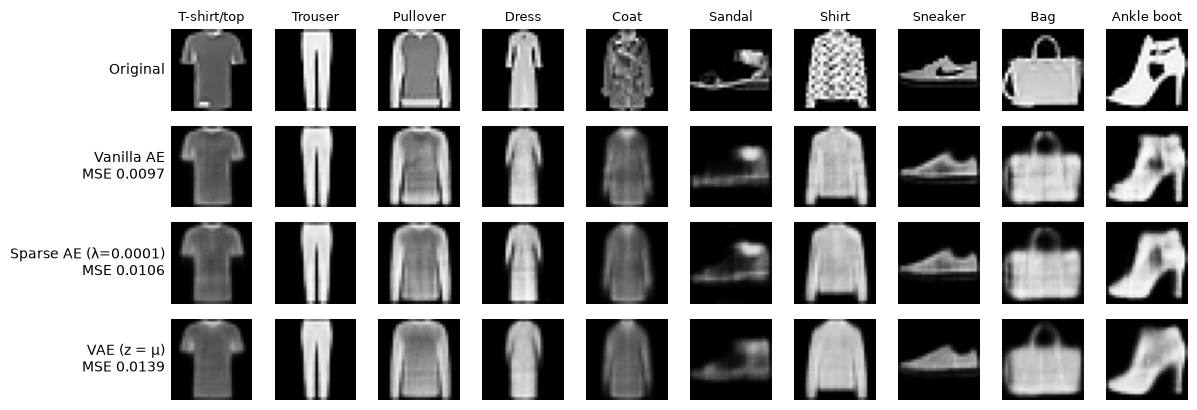

In [ ]:
# reconstruction of one test image per class; each row label carries the model's test MSE
from src.utils import show_rows

with torch.no_grad():
    rec = {
        "Original": x_pick,
        f"Vanilla AE\nMSE {res['Vanilla AE']['mse']:.4f}": ae(x_pick)[0],
        f"Sparse AE (λ={best_lam})\nMSE {res['Sparse AE']['mse']:.4f}": sae_best(x_pick)[0],
        f"VAE (z = μ)\nMSE {res['VAE']['mse']:.4f}": vae.dec(vae.encode(x_pick)[0]),
    }
show_rows({k: v.view(-1, 1, 28, 28) for k, v in rec.items()}, col_titles=CLASSES,
          path=FIG_DIR / "fig1_reconstruction.png")

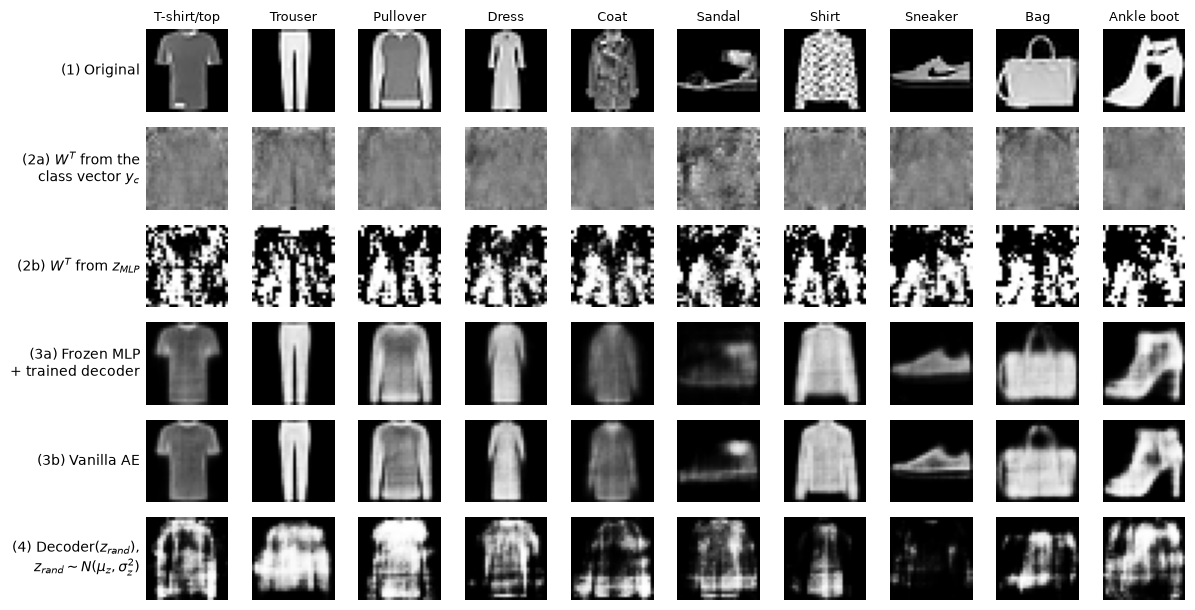

In [ ]:
# why the MLP classifier cannot generate, on the same 10 test images
# rows 1-3 share the columns (one class each); row 4 = 10 random samples, so its columns are not classes
from src.utils import show_rows

model.eval(); decoder.eval(); ae.eval()
mu_mlp, sd_mlp = z_mlp.mean(0), z_mlp.std(0)
with torch.no_grad():
    z_pick = model(x_pick)[1]                                                  # z_MLP of the 10 originals
    y_onehot = torch.eye(10, device=DEVICE)
    proj_class = torch.sigmoid(F.relu(F.relu(y_onehot @ W3) @ W2) @ W1)       # Step 2: from the class vector
    proj_z = torch.sigmoid(F.relu(z_pick @ W2) @ W1)                           # Step 3: from z_MLP
    rec_frozen = decoder(z_pick)                                               # Step 4: trained decoder, frozen MLP
    rec_ae10 = ae(x_pick)[0]                                                   # Step 4 reference: Vanilla AE, same z size
    set_seed(42)
    smp_mlp = decoder((mu_mlp + sd_mlp * torch.randn(10, 64)).to(DEVICE))     # Step 5: prior sampling

v = lambda t: t.view(-1, 1, 28, 28)
show_rows({"(1) Original": x_pick,
           "(2a) $W^T$ from the\nclass vector $y_c$": v(proj_class),
           "(2b) $W^T$ from $z_{MLP}$": v(proj_z),
           "(3a) Frozen MLP\n+ trained decoder": v(rec_frozen),
           "(3b) Vanilla AE": v(rec_ae10),
           "(4) Decoder($z_{rand}$),\n$z_{rand} \\sim N(\\mu_z, \\sigma_z^2)$": v(smp_mlp)},
          col_titles=CLASSES, path=FIG_DIR / "fig3_mlp_limits.png")

In [ ]:
# the three limits of the MLP classifier, measured on the test set
model.eval()
with torch.no_grad():
    se_back, zero_h1, zero_z, n = 0.0, 0.0, 0.0, 0
    for x, _ in test_dl:
        xf = x.to(DEVICE).flatten(1)
        h1 = F.relu(model.fc1(xf))
        z = F.relu(model.fc2(h1))
        back = torch.sigmoid(F.relu(z @ W2) @ W1)                 # Step 3 back-projection
        se_back += ((back - xf) ** 2).mean(1).sum().item()
        zero_h1 += (h1 == 0).float().mean(1).sum().item()
        zero_z += (z == 0).float().mean(1).sum().item()
        n += xf.size(0)
print("Test-set pixel MSE when going back from z (64 numbers per image):")
print(f"  W^T back-projection (Tahap 3)    {se_back / n:.4f}")
print(f"  frozen MLP + decoder (Tahap 4)   {res['MLP + frozen decoder']['mse']:.4f}")
print(f"  Vanilla AE (z_AE, also 64)       {res['Vanilla AE']['mse']:.4f}")

# W is not orthogonal and W^T W cannot be the identity (a matrix with r rows has rank <= r)
print("\nLimit 2, the weights are not invertible:")
for name, W in [("W1", W1), ("W2", W2), ("W3", W3)]:
    s = torch.linalg.svdvals(W)
    WtW = W.T @ W
    I = torch.eye(WtW.size(0), device=W.device)
    print(f"  {name} {tuple(W.shape)}: W^T W is {WtW.size(0)}x{WtW.size(0)} but has rank {int((s > 1e-6 * s.max()).sum())}; "
          f"||W^T W - I|| / ||I|| = {(torch.linalg.norm(WtW - I) / torch.linalg.norm(I)).item():.2f}; "
          f"singular values {s.min().item():.2f} to {s.max().item():.2f} (all 1 if orthogonal)")
print(f"  ReLU sets {zero_h1 / n:.0%} of h1 and {zero_z / n:.0%} of z_MLP to exactly 0 per image: that input is lost")

# the information bottleneck of P(y|x) -> how much latent variance is left WITHIN each class?
def within_class_share(z, y):
    z = z - z.mean(0)
    within = sum(((z[y == c] - z[y == c].mean(0)) ** 2).sum() for c in range(10))
    return (within / (z ** 2).sum()).item()
print(f"\nLimit 1, within-class share of latent variance (intra-class detail kept): "
      f"z_MLP {within_class_share(z_mlp, y_test):.0%} vs z_AE {within_class_share(z_ae, y_test):.0%}")

# no density prior P(z) -> a Gaussian fitted to z_MLP puts mass where real codes never are
set_seed(42)
z_samp = mu_mlp + sd_mlp * torch.randn(10000, 64)
print(f"Limit 3, real z_MLP entries exactly 0: {(z_mlp == 0).float().mean():.0%}; never negative. "
      f"Samples from N(mu_z, sigma_z^2) below 0: {(z_samp < 0).float().mean():.0%}")

Test-set pixel MSE when going back from z (64 numbers per image):
  W^T back-projection (Tahap 3)    0.2748
  frozen MLP + decoder (Tahap 4)   0.0166
  Vanilla AE (z_AE, also 64)       0.0097

Limit 2, the weights are not invertible:
  W1 (256, 784): W^T W is 784x784 but has rank 256; ||W^T W - I|| / ||I|| = 9.41; singular values 0.33 to 11.40 (all 1 if orthogonal)
  W2 (64, 256): W^T W is 256x256 but has rank 64; ||W^T W - I|| / ||I|| = 2.49; singular values 0.36 to 5.05 (all 1 if orthogonal)
  W3 (10, 64): W^T W is 64x64 but has rank 10; ||W^T W - I|| / ||I|| = 1.09; singular values 0.72 to 2.12 (all 1 if orthogonal)
  ReLU sets 53% of h1 and 43% of z_MLP to exactly 0 per image: that input is lost

Limit 1, within-class share of latent variance (intra-class detail kept): z_MLP 30% vs z_AE 59%
Limit 3, real z_MLP entries exactly 0: 43%; never negative. Samples from N(mu_z, sigma_z^2) below 0: 15%


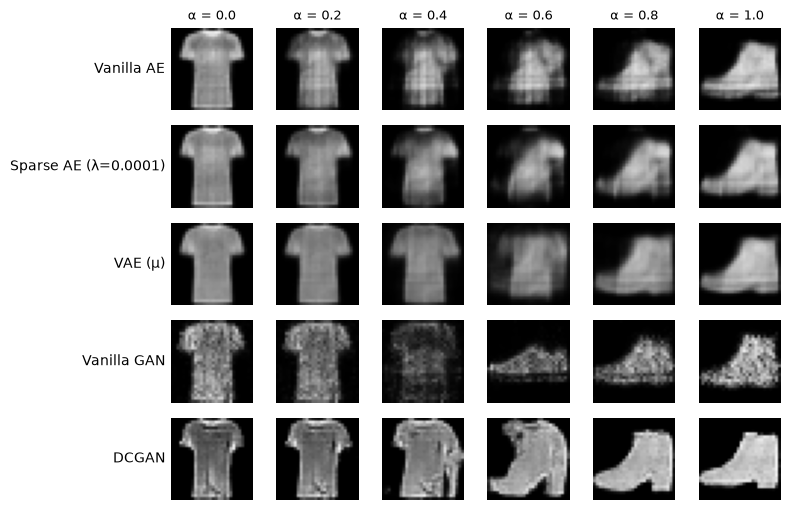

Vanilla AE           T-shirt/t 1.00 | T-shirt/t 0.80 | Shirt     0.45 | Sneaker   0.59 | Ankle boo 0.58 | Ankle boo 0.98
Sparse AE (λ=0.0001) T-shirt/t 1.00 | T-shirt/t 0.99 | T-shirt/t 0.88 | T-shirt/t 0.61 | Ankle boo 0.70 | Ankle boo 0.99
VAE (μ)              T-shirt/t 1.00 | T-shirt/t 0.99 | T-shirt/t 0.90 | Bag       0.93 | Ankle boo 0.97 | Ankle boo 0.99
Vanilla GAN          T-shirt/t 0.98 | T-shirt/t 0.97 | T-shirt/t 0.57 | Sneaker   0.99 | Sneaker   0.67 | Ankle boo 0.85
DCGAN                T-shirt/t 1.00 | T-shirt/t 0.99 | Pullover  0.80 | Ankle boo 1.00 | Ankle boo 1.00 | Ankle boo 1.00


In [ ]:
# linear latent interpolation z(α) = (1 - α) z_A + α z_B between two contrasting classes
from src.utils import show_rows

alphas = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
lerp = lambda zA, zB: torch.stack([(1 - a) * zA + a * zB for a in alphas])

# endpoints: the most typical T-shirt/top and Ankle boot of the test set (closest to their class's average image)
X_test = torch.cat([x for x, _ in test_dl])
def typical(c):
    xc = X_test[y_test == c]
    return xc[((xc - xc.mean(0)) ** 2).flatten(1).mean(1).argmin()].unsqueeze(0).to(DEVICE)
xA, xB = typical(0), typical(9)

def gan_endpoints(G, n=5000):
    """GANs have no encoder: among n random noise vectors, take the two whose images are closest (pixel MSE)
    to xA and xB, so every row interpolates between similar pictures."""
    set_seed(42)
    z = torch.randn(n, Z_DIM, device=DEVICE)
    imgs = torch.cat([(G(part) + 1) / 2 for part in z.split(1000)])
    return z[((imgs - xA) ** 2).flatten(1).mean(1).argmin()], z[((imgs - xB) ** 2).flatten(1).mean(1).argmin()]

for m in (ae, sae_best, vae, G_gan, G_dc, model):
    m.eval()
with torch.no_grad():
    paths = {
        "Vanilla AE": ae.dec(lerp(ae.enc(xA)[0], ae.enc(xB)[0])),
        f"Sparse AE (λ={best_lam})": sae_best.dec(lerp(sae_best.enc(xA)[0], sae_best.enc(xB)[0])),
        "VAE (μ)": vae.dec(lerp(vae.encode(xA)[0][0], vae.encode(xB)[0][0])),
        "Vanilla GAN": (G_gan(lerp(*gan_endpoints(G_gan))) + 1) / 2,
        "DCGAN": (G_dc(lerp(*gan_endpoints(G_dc))) + 1) / 2,
    }
paths = {k: v.view(-1, 1, 28, 28) for k, v in paths.items()}
show_rows(paths, col_titles=[f"α = {a}" for a in alphas], path=FIG_DIR / "fig4_interpolation.png")

# what the classifier sees along each path: predicted class and its confidence at every α
with torch.no_grad():
    for name, imgs in paths.items():
        conf, cls = F.softmax(model(imgs)[0], dim=1).max(1)
        print(f"{name:20}", " | ".join(f"{CLASSES[c][:9]:9} {q:.2f}" for c, q in zip(cls.tolist(), conf.tolist())))

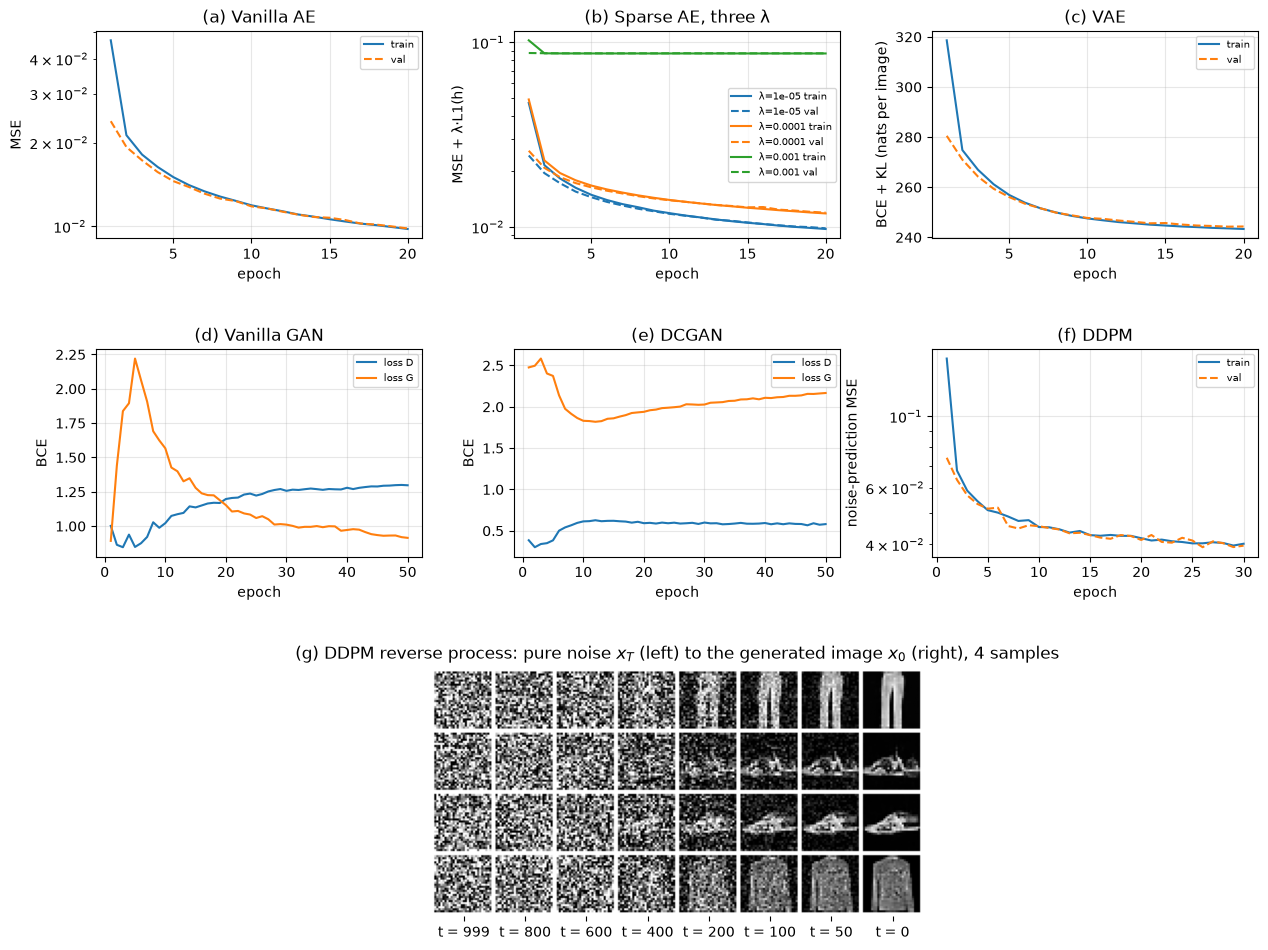

In [ ]:
# training curves of all six models (from the saved histories) + the DDPM reverse process
from torchvision.utils import make_grid

Hs = {n: load_history(n) for n in ["ae", "vae", "gan", "dcgan", "ddpm"] + [f"sae_lam{lam}" for lam in LAMS]}
ep = lambda h, key="train_loss": np.arange(1, len(h[key]) + 1)

fig = plt.figure(figsize=(15, 11.5))
gs = fig.add_gridspec(3, 3, height_ratios=[1, 1, 1.2], hspace=0.5, wspace=0.28)
ax = [fig.add_subplot(gs[r, c]) for r in range(2) for c in range(3)]

h = Hs["ae"]
ax[0].plot(ep(h), h["train_loss"], label="train")
ax[0].plot(ep(h), h["val_loss"], "--", label="val")
ax[0].set(title="(a) Vanilla AE", ylabel="MSE", yscale="log")

for i, lam in enumerate(LAMS):
    h = Hs[f"sae_lam{lam}"]
    ax[1].plot(ep(h), h["train_loss"], color=f"C{i}", label=f"λ={lam} train")
    ax[1].plot(ep(h), h["val_loss"], "--", color=f"C{i}", label=f"λ={lam} val")
ax[1].set(title="(b) Sparse AE, three λ", ylabel="MSE + λ·L1(h)", yscale="log")

h = Hs["vae"]
ax[2].plot(ep(h), h["train_loss"], label="train")
ax[2].plot(ep(h), h["val_loss"], "--", label="val")
ax[2].set(title="(c) VAE", ylabel="BCE + KL (nats per image)")

for k, (name, title) in enumerate([("gan", "(d) Vanilla GAN"), ("dcgan", "(e) DCGAN")]):
    h, a = Hs[name], ax[3 + k]
    a.plot(ep(h, "loss_D"), h["loss_D"], label="loss D")
    a.plot(ep(h, "loss_G"), h["loss_G"], label="loss G")
    a.set(title=title, ylabel="BCE")

h = Hs["ddpm"]
ax[5].plot(ep(h), h["train_loss"], label="train")
ax[5].plot(ep(h), h["val_loss"], "--", label="val")
ax[5].set(title="(f) DDPM", ylabel="noise-prediction MSE", yscale="log")

for a in ax:
    a.set_xlabel("epoch")
    a.grid(alpha=0.3)
    a.legend(fontsize=7)

# bottom panel: 4 samples (rows) going from pure noise x_T (left) to the generated image x_0 (right)
order = sorted(traj, reverse=True)
grid = make_grid(torch.stack([traj[t][:4] for t in order], dim=1).flatten(0, 1), nrow=len(order), padding=2, pad_value=1.0)
axt = fig.add_subplot(gs[2, :])
axt.imshow(grid[0], cmap="gray", vmin=0, vmax=1)
axt.set_xticks([2 + 30 * i + 14 for i in range(len(order))], [f"t = {t}" for t in order])
axt.set_yticks([])
for spine in axt.spines.values():
    spine.set_visible(False)
axt.set_title("(g) DDPM reverse process: pure noise $x_T$ (left) to the generated image $x_0$ (right), 4 samples")

plt.savefig(FIG_DIR / "fig5_training_and_trajectory.png", dpi=300, bbox_inches="tight")
plt.show()

| Model              |   near-zero share |   active units / image |   dead units (never active) |   mean h |   Test MSE |   Test PSNR (dB) |   Test SSIM |
|:-------------------|------------------:|-----------------------:|----------------------------:|---------:|-----------:|-----------------:|------------:|
| Vanilla AE         |            0.3917 |                38.9319 |                          23 |   2.6890 |     0.0097 |          21.0493 |      0.8053 |
| Sparse AE λ=1e-05  |            0.3407 |                42.1969 |                          16 |   0.7785 |     0.0092 |          21.3060 |      0.8134 |
| Sparse AE λ=0.0001 |            0.5592 |                28.2087 |                          29 |   0.1773 |     0.0106 |          20.6090 |      0.7829 |
| Sparse AE λ=0.001  |            1.0000 |                 0.0000 |                          64 |   0.0000 |     0.0868 |          10.9278 |      0.1597 |


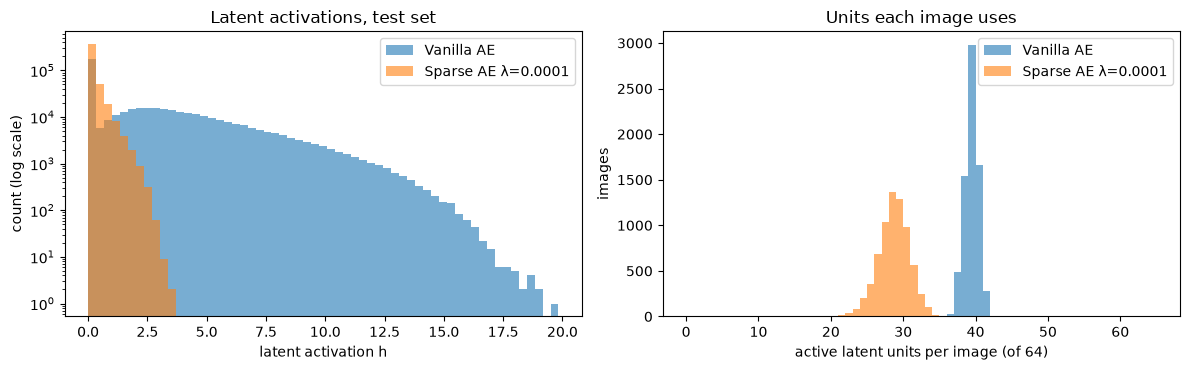

In [ ]:
# what the L1 penalty does to the latent code h (test set), all three λ against the Vanilla AE
import pandas as pd
from src.utils import METRIC_DIR

rows_sp, codes = [], {}
for name, m in [("Vanilla AE", ae)] + [(f"Sparse AE λ={lam}", saes[lam]) for lam in LAMS]:
    m.eval()
    h, _ = extract_latents(m, test_dl)                    # (7000, 64), after the encoder's ReLU
    codes[name] = h
    active = h > 1e-3
    r = recon_metrics(lambda x: m(x)[0])
    rows_sp.append({"Model": name, "near-zero share": 1 - active.float().mean().item(),
                    "active units / image": active.sum(1).float().mean().item(),
                    "dead units (never active)": int((active.sum(0) == 0).sum()),
                    "mean h": h.mean().item(),
                    "Test MSE": r["mse"], "Test PSNR (dB)": r["psnr"], "Test SSIM": r["ssim"]})
df_sp = pd.DataFrame(rows_sp)
df_sp.to_csv(METRIC_DIR / "sae_sweep.csv", index=False)
print(df_sp.to_markdown(index=False, floatfmt=".4f"))

# left: distribution of all activations; right: how many of the 64 units each image switches on
h_ae, h_sae = codes["Vanilla AE"], codes[f"Sparse AE λ={best_lam}"]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
bins = np.linspace(0, float(max(h_ae.max(), h_sae.max())), 60)
axs[0].hist(h_ae.flatten().numpy(), bins=bins, alpha=0.6, label="Vanilla AE")
axs[0].hist(h_sae.flatten().numpy(), bins=bins, alpha=0.6, label=f"Sparse AE λ={best_lam}")
axs[0].set(yscale="log", xlabel="latent activation h", ylabel="count (log scale)", title="Latent activations, test set")
units = np.arange(0, 66)
axs[1].hist((h_ae > 1e-3).sum(1).numpy(), bins=units, alpha=0.6, label="Vanilla AE")
axs[1].hist((h_sae > 1e-3).sum(1).numpy(), bins=units, alpha=0.6, label=f"Sparse AE λ={best_lam}")
axs[1].set(xlabel="active latent units per image (of 64)", ylabel="images", title="Units each image uses")
for a in axs:
    a.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "q2_sparsity.png", dpi=300, bbox_inches="tight")
plt.show()

| Model                |   AUROC hole, mean MSE |   AUROC hole, worst 6x6 |   AUROC stain, mean MSE |   AUROC stain, worst 6x6 |
|:---------------------|-----------------------:|------------------------:|------------------------:|-------------------------:|
| Vanilla AE           |                  0.794 |                   0.844 |                   0.782 |                    0.793 |
| Sparse AE (λ=0.0001) |                  0.796 |                   0.852 |                   0.783 |                    0.809 |
| VAE (z = μ)          |                  0.823 |                   0.910 |                   0.803 |                    0.859 |


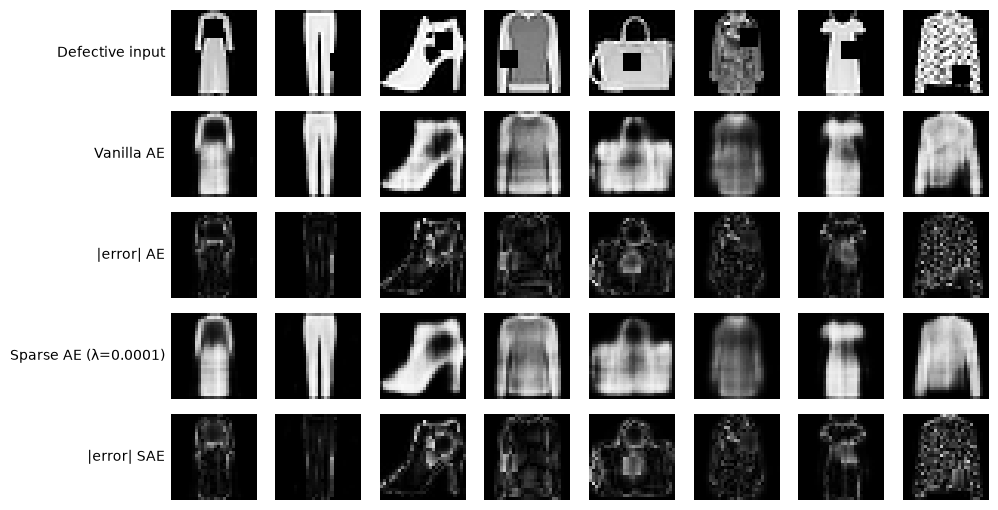


CPU latency in ms (mobile proxy):
|   batch |   VAE decoder |   Vanilla GAN G |   DCGAN G |   DDPM, 1 step |   DDPM, 1,000 steps (est.) |
|--------:|--------------:|----------------:|----------:|---------------:|---------------------------:|
|    1.00 |          0.06 |            0.10 |      0.48 |           5.89 |                   5,894.66 |
|   64.00 |          0.25 |            0.89 |      4.81 |         178.49 |                 178,491.06 |


In [ ]:
# unsupervised anomaly detection on simulated manufacturing defects, scored by reconstruction error
import copy, time
import pandas as pd
from sklearn.metrics import roc_auc_score
from src.utils import show_rows, METRIC_DIR

def add_defects(x, kind, gen):
    """'hole': a 6x6 patch of the item removed (set to black); 'stain': a 6x6 bright patch anywhere."""
    x = x.clone()
    for i in range(x.size(0)):
        if kind == "hole":                                       # place it on the item itself
            ys, xs = torch.nonzero(x[i, 0, 3:19, 3:19] > 0.3, as_tuple=True)
            if len(ys) == 0:
                continue
            k = torch.randint(len(ys), (1,), generator=gen).item()
            r, c = ys[k].item() + 3, xs[k].item() + 3
        else:
            r, c = torch.randint(3, 19, (2,), generator=gen).tolist()
        x[i, :, r:r + 6, c:c + 6] = 0.0 if kind == "hole" else 1.0
    return x

@torch.no_grad()
def scores(fn, X):
    """Two anomaly scores per image: mean squared error, and the worst 6x6 window of the error map."""
    mean_e, win_e = [], []
    for part in X.split(500):
        part = part.to(DEVICE)
        err = (fn(part).view_as(part) - part) ** 2
        mean_e.append(err.flatten(1).mean(1).cpu())
        win_e.append(F.avg_pool2d(err, 6, stride=1).flatten(1).max(1).values.cpu())
    return torch.cat(mean_e), torch.cat(win_e)

gen = torch.Generator().manual_seed(42)
X = torch.cat([x for x, _ in test_dl])                          # the 7,000 normal test images
defective = {"hole": add_defects(X, "hole", gen), "stain": add_defects(X, "stain", gen)}
recon = {"Vanilla AE": lambda x: ae(x)[0],
         f"Sparse AE (λ={best_lam})": lambda x: sae_best(x)[0],
         "VAE (z = μ)": lambda x: vae.dec(vae.encode(x)[0])}

rows_q6 = []
for name, fn in recon.items():
    n_mean, n_win = scores(fn, X)
    row = {"Model": name}
    for kind, Xd in defective.items():
        d_mean, d_win = scores(fn, Xd)
        y = np.r_[np.zeros(len(X)), np.ones(len(Xd))]
        row[f"AUROC {kind}, mean MSE"] = roc_auc_score(y, np.r_[n_mean.numpy(), d_mean.numpy()])
        row[f"AUROC {kind}, worst 6x6"] = roc_auc_score(y, np.r_[n_win.numpy(), d_win.numpy()])
    rows_q6.append(row)
df_q6 = pd.DataFrame(rows_q6)
df_q6.to_csv(METRIC_DIR / "anomaly_auroc.csv", index=False)
print(df_q6.to_markdown(index=False, floatfmt=".3f"))

# where the error shows up: 8 test images with a hole, their reconstructions and |error| maps
Xd8 = defective["hole"][:8].to(DEVICE)
with torch.no_grad():
    r_ae, r_sae = ae(Xd8)[0].view_as(Xd8), sae_best(Xd8)[0].view_as(Xd8)
show_rows({"Defective input": Xd8, "Vanilla AE": r_ae, "|error| AE": (r_ae - Xd8).abs(),
           f"Sparse AE (λ={best_lam})": r_sae, "|error| SAE": (r_sae - Xd8).abs()},
          path=FIG_DIR / "q6_anomaly_maps.png")

# latency budget < 30 ms on a phone. Proxy: this laptop's CPU, one image and a batch of 64
def cpu_ms(fn, reps=30, warmup=5):
    with torch.no_grad():
        for _ in range(warmup):
            fn()
        t0 = time.perf_counter()
        for _ in range(reps):
            fn()
    return (time.perf_counter() - t0) / reps * 1000

vae_c, gan_c, dc_c, unet_c = (copy.deepcopy(m).cpu().eval() for m in (vae, G_gan, G_dc, unet))
rows_cpu = []
for b in (1, 64):
    rows_cpu.append({"batch": b,
                     "VAE decoder": cpu_ms(lambda: vae_c.dec(torch.randn(b, 64))),
                     "Vanilla GAN G": cpu_ms(lambda: gan_c(torch.randn(b, Z_DIM))),
                     "DCGAN G": cpu_ms(lambda: dc_c(torch.randn(b, Z_DIM))),
                     "DDPM, 1 step": cpu_ms(lambda: unet_c(torch.randn(b, 1, 28, 28), torch.full((b,), 500)), reps=10)})
df_cpu = pd.DataFrame(rows_cpu)
df_cpu["DDPM, 1,000 steps (est.)"] = df_cpu["DDPM, 1 step"] * 1000
df_cpu.to_csv(METRIC_DIR / "cpu_latency_ms.csv", index=False)
print("\nCPU latency in ms (mobile proxy):")
print(df_cpu.to_markdown(index=False, floatfmt=",.2f"))